# NSSC 2026 · Data Analytics
## Unsupervised Anomaly Detection in Mars HiRISE Orbital Imagery

**Team:** OrbitIQ · National Students' Space Challenge, IIT Kharagpur

**Pipeline:** custom two-stage convolutional autoencoder (trained from scratch, no pretrained weights) →
1-D latent vector per crop → Isolation Forest Novelty Score (higher = more anomalous) →
statistically justified threshold → metadata join → pixel-wise reconstruction-error heatmaps →
physical hypotheses. Six model versions (v1 → v6) are trained and compared; the changelog
(Phase 4 and `CHANGELOG.md`) documents each symptom → diagnosis → fix step.

| Section | Content |
|---|---|
| 0 | Setup, data loading, sanity pass, no-data masking |
| 1.1 / 1.2 / 1.3 | Architecture, loss design, training of v1-v6, t-SNE of latents |
| 2.1 / 2.2 / 2.3 / 2.4 | Isolation Forest scoring, statistical threshold, location analysis, metadata fusion |
| 3.1 / 3.2 | Top-5 error heatmaps and geological report |
| 4 | Iteration journal (v1 → v6) and planted-fakes benchmark |

Reproduce: place `images.zip` (extracted to `data/images_unz/images/`), `crop_metadata_index.csv` and
`source_image_metadata.csv` in `data/`, then run all cells. With `RETRAIN=False` the notebook loads
checkpoints in `outputs/vN/model.pt` that were produced by exactly the code in this notebook.

## 0. Setup

In [1]:
# ---- nssc_core.py :: setup
import os, glob, json, math, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from scipy import ndimage, stats

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
IMG_SIZE = 227
IMG_EXTS = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")
# bf16 autocast only where the GPU supports it natively (Ampere+); fp32 elsewhere, e.g. a Colab T4
USE_BF16 = DEVICE.type == "cuda" and torch.cuda.get_device_capability()[0] >= 8


def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True   # reproducible up to residual GPU non-determinism
    torch.backends.cudnn.benchmark = False

In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "font.size": 9})
ROOT = os.path.abspath(".")
DATA, OUT, CACHE = [os.path.join(ROOT, d) for d in ("data", "outputs", "cache")]
IMG_DIR = os.path.join(DATA, "images_unz", "images")      # images.zip extracted here
FIG = os.path.join(OUT, "figures"); os.makedirs(FIG, exist_ok=True); os.makedirs(CACHE, exist_ok=True)
RETRAIN = False     # True: retrain every version from scratch (~6 min each on an RTX 5070 Laptop GPU)
VERSIONS = ["v1", "v2", "v3", "v4", "v5", "v6"]
FINAL = "v6"        # version used for Phases 2-3: two-stage model (v4, v5 tried and rejected - see changelog)
seed_everything(42)
print("torch", torch.__version__, "| device:", DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "")
def savefig(name): plt.savefig(os.path.join(FIG, name), dpi=130, bbox_inches="tight")

torch 2.11.0+cu128 | device: cuda NVIDIA GeForce RTX 5070 Laptop GPU


In [3]:
# Google Colab / fresh-machine support: fetch the competition data if it is not already present
# (a no-op when data/ exists). Source: the organisers' Google Drive folder linked in the rules PDF.
import sys, subprocess, zipfile
DATA_URL = "https://drive.google.com/drive/folders/19RPd0thhM5CI4xrImE0Jjlak9GPZwC_O"
if not os.path.exists(os.path.join(DATA, "crop_metadata_index.csv")):
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gdown"], check=True)
    subprocess.run([sys.executable, "-m", "gdown", "--folder", DATA_URL, "-O", DATA], check=True)
if not os.path.isdir(IMG_DIR):
    zipfile.ZipFile(os.path.join(DATA, "images.zip")).extractall(os.path.join(DATA, "images_unz"))
print("running on", "Google Colab" if "google.colab" in sys.modules else "local Jupyter", "| data ready:", os.path.isdir(IMG_DIR))

running on local Jupyter | data ready: True


In [4]:
# ---- nssc_core.py :: configs
# Every model version documented in the changelog (Phase 4). Each later version changes one
# thing motivated by an observed failure of the previous one - see CHANGELOG.md.
CONFIGS = {
    "v1": dict(model=dict(latent_dim=256, up="transpose", res_blocks=0, variational=False),
               loss=dict(w_mse=1.0), epochs=30, lr=1e-3),
    # v2: fix MSE blur -> structural (SSIM) + robust intensity (L1) + edge (gradient) loss
    "v2": dict(model=dict(latent_dim=256, up="transpose", res_blocks=0, variational=False),
               loss=dict(w_mse=0.0, w_l1=0.16, w_ssim=0.84, w_grad=0.1), epochs=30, lr=1e-3),
    # v3: remove the no-data nuisance -> mask map-projection wedges, fill with crop median,
    #     exclude them from the loss (and from reconstruction-error maps)
    "v3": dict(model=dict(latent_dim=256, up="transpose", res_blocks=0, variational=False),
               loss=dict(w_mse=0.0, w_l1=0.16, w_ssim=0.84, w_grad=0.1), epochs=30, lr=1e-3,
               nodata=True),
    # v4: keep local defects visible to the Isolation Forest -> spatial 8x8x4 bottleneck
    #     (1x1 conv instead of a global Linear), same 256-d 1-D latent, same loss and masking as v3
    "v4": dict(model=dict(latent_dim=256, up="transpose", res_blocks=0, variational=False, spatial_latent=4),
               loss=dict(w_mse=0.0, w_l1=0.16, w_ssim=0.84, w_grad=0.1), epochs=30, lr=1e-3,
               nodata=True),
    # v5: remove v3's brightness bias -> per-crop photometric normalisation (on top of v3)
    "v5": dict(model=dict(latent_dim=256, up="transpose", res_blocks=0, variational=False),
               loss=dict(w_mse=0.0, w_l1=0.16, w_ssim=0.84, w_grad=0.1), epochs=30, lr=1e-3,
               nodata=True, standardize=True),
    # v6: two-stage autoencoder -> stage 2 compresses stage 1's reconstruction residual into a
    #     64-d code; final latent = [256-d scene code | 64-d residual code] (320-d, 1-D)
    "v6": dict(model=dict(latent_dim=64, up="transpose", res_blocks=0, variational=False),
               loss=dict(w_mse=1.0, w_l1=0.5), epochs=30, lr=1e-3, nodata=True, residual_of="v3"),
}

## 0.1 Data loading and sanity pass

In [5]:
# ---- nssc_core.py :: data
def list_images(root):
    files = [p for p in glob.glob(os.path.join(root, "**", "*"), recursive=True)
             if p.lower().endswith(IMG_EXTS)]
    return sorted(files)


def load_images(files, cache_path=None):
    """Load every crop as uint8 [N, 227, 227]. Cached to .npy after first load."""
    if cache_path and os.path.exists(cache_path):
        return np.load(cache_path)
    arr = np.empty((len(files), IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    for i, f in enumerate(files):
        im = Image.open(f).convert("L")
        if im.size != (IMG_SIZE, IMG_SIZE):  # dataset is standardised; guard only
            im = im.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
        arr[i] = np.asarray(im)
    if cache_path:
        np.save(cache_path, arr)
    return arr

In [6]:
crop_index = pd.read_csv(os.path.join(DATA, "crop_metadata_index.csv"))
source_meta = pd.read_csv(os.path.join(DATA, "source_image_metadata.csv"))
files = [os.path.join(IMG_DIR, f) for f in crop_index.filename]
X = load_images(files, cache_path=os.path.join(CACHE, "images_u8.npy"))
assert len(X) == len(crop_index) and set(crop_index.source_image_id) == set(source_meta.source_image_id)
print(f"{len(X)} crops | {crop_index.source_image_id.nunique()} source observations | array {X.shape} {X.dtype}")
print(f"pixel range [{X.min()}, {X.max()}]  mean {X.mean():.1f}  -> rescaled to [0, 1] by /255 at batch time")
flat = X.reshape(len(X), -1)
nodata = (flat <= 2).mean(1)            # share of near-black map-projection no-data pixels
img_mean, img_std = flat.mean(1) / 255, flat.std(1) / 255
print(f"crops with a black no-data border (>1% of pixels): {(nodata > .01).mean():.1%}")
print(f"crops with >1% saturated-white pixels: {((flat >= 253).mean(1) > .01).sum()}")

10422 crops | 172 source observations | array (10422, 227, 227) uint8


pixel range [0, 255]  mean 119.3  -> rescaled to [0, 1] by /255 at batch time


crops with a black no-data border (>1% of pixels): 19.8%


crops with >1% saturated-white pixels: 6


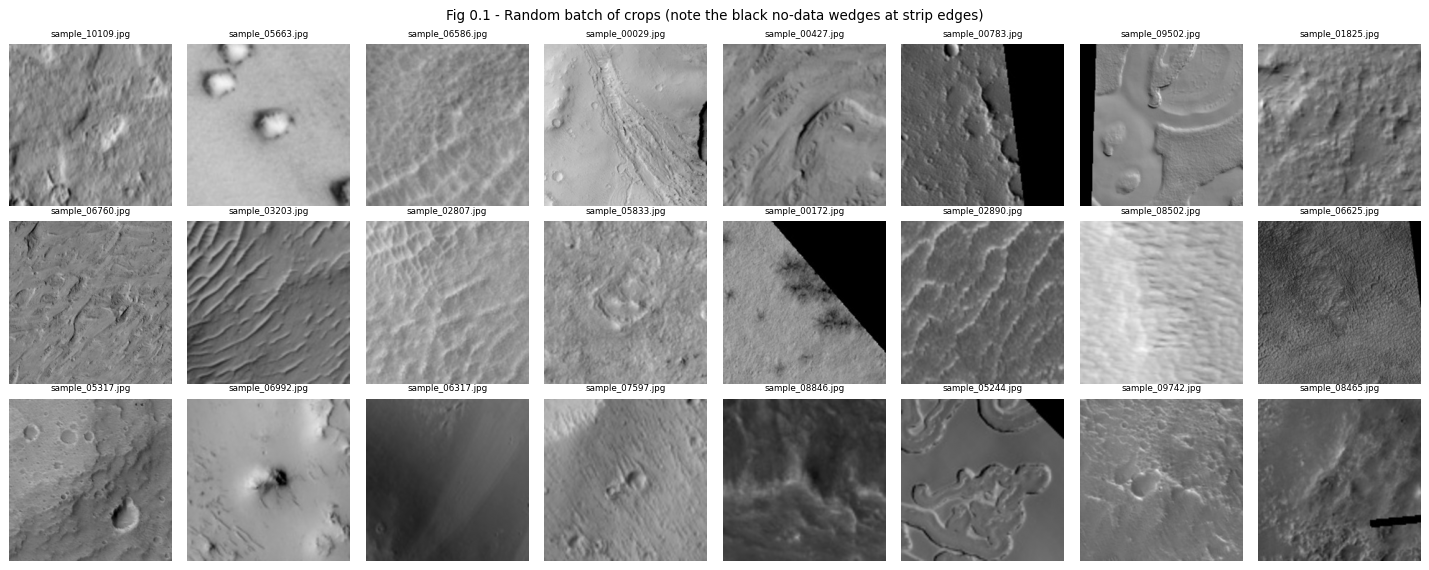

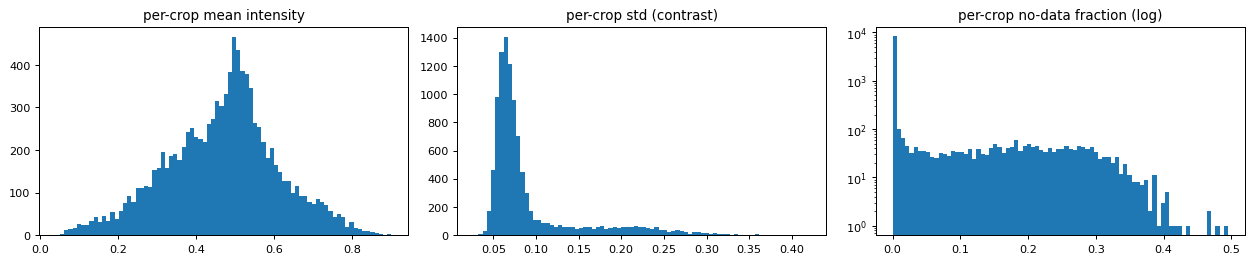

In [7]:
rng = np.random.default_rng(0); sel = rng.choice(len(X), 24, replace=False)
fig, ax = plt.subplots(3, 8, figsize=(16, 6.4))
for a, i in zip(ax.ravel(), sel):
    a.imshow(X[i], cmap="gray", vmin=0, vmax=255); a.set_title(crop_index.filename[i], fontsize=7); a.axis("off")
plt.suptitle("Fig 0.1 - Random batch of crops (note the black no-data wedges at strip edges)"); plt.tight_layout(); savefig("fig01_random_batch.png"); plt.show()
fig, ax = plt.subplots(1, 3, figsize=(14, 3))
ax[0].hist(img_mean, 80); ax[0].set_title("per-crop mean intensity")
ax[1].hist(img_std, 80); ax[1].set_title("per-crop std (contrast)")
ax[2].hist(nodata, 80, log=True); ax[2].set_title("per-crop no-data fraction (log)")
plt.tight_layout(); savefig("fig02_pixel_stats.png"); plt.show()

**Sanity-pass findings**

* 10,422 single-channel 227×227 JPEG crops from 172 source observations; every crop maps to exactly
  one `source_image_id` and every id has metadata (checked with `assert`).
* Pixel values span the full 0-255 range; we rescale by 1/255 to [0, 1] and use a sigmoid decoder output.
* **≈20 % of crops contain a solid-black no-data wedge** (the map-projected edge of the HiRISE strip).
  These are *normal* data, but they are the highest-contrast edges in the whole dataset, which matters
  for both the reconstruction loss and the anomaly detector (see changelog).
* Very bright crops (frost / dust) exist and are genuine terrain, so a brightness heuristic
  cannot separate anomalies - consistent with the organisers' warning.

## 0.2 No-data (map-projection) masking - introduced in v3

v1 and v2 showed that the black map-projection wedges, which are *normal* data, dominated both the
reconstruction loss and the latent space (see changelog). From v3 on, each crop gets a **no-data
mask**. A pixel is masked if it belongs to a near-black (≤ 5) region that

* survives a 5×5 morphological opening, so thin dark lines are *not* masked. A dead sensor
  column or a black streak could itself be an injected anomaly, and hiding it would be wrong.
* touches the crop border, because strip edges enter from outside the crop.
* covers at least 0.5 % of the crop.

The mask is dilated by 2 px to cover JPEG ringing along the wedge edge. Masked pixels are filled
with the median of the crop's valid pixels, which gives a flat, texture-free region with no
razor-sharp edge. They are also **excluded from the loss and from every reconstruction-error
metric and heatmap**. The filled image, not the original, is what the v3 encoder sees.

In [8]:
# ---- nssc_core.py :: nodata
def nodata_mask(img_u8, thr=5, min_area=0.005, open_px=5, dilate_px=2):
    """Map-projection no-data of one crop (True = no-data).

    A pixel is no-data if it belongs to a near-black (<= thr) connected region that
    (a) survives a 5x5 morphological opening - so thin dark lines, e.g. a dead sensor
        column that could itself be an anomaly, are NOT masked,
    (b) touches the crop border - strip edges enter from outside the crop, and
    (c) covers >= 0.5% of the crop.
    The mask is dilated by 2 px to cover JPEG ringing along the wedge edge.
    """
    m = ndimage.binary_opening(img_u8 <= thr, structure=np.ones((open_px, open_px)))
    if not m.any():
        return m
    lab, n = ndimage.label(m)
    edge = np.unique(np.concatenate([lab[0], lab[-1], lab[:, 0], lab[:, -1]]))
    sizes = ndimage.sum(m, lab, index=np.arange(n + 1))
    keep = np.zeros(n + 1, bool)
    keep[edge] = True
    keep[0] = False
    keep &= sizes >= min_area * m.size
    out = keep[lab]
    return ndimage.binary_dilation(out, iterations=dilate_px) if out.any() else out


def compute_nodata_masks(X, cache_path=None):
    if cache_path and os.path.exists(cache_path):
        return np.load(cache_path)
    M = np.stack([nodata_mask(x) for x in X]).astype(np.uint8)
    if cache_path:
        np.save(cache_path, M)
    return M


def fill_nodata(X, M):
    """Replace no-data pixels by the median of the crop's valid pixels (a flat, texture-free fill)."""
    Xf = X.copy()
    for i in np.where(M.reshape(len(M), -1).any(1))[0]:
        valid = X[i][M[i] == 0]
        Xf[i][M[i] == 1] = np.uint8(np.median(valid)) if valid.size else 0
    return Xf


def standardize_images(X, M=None, target_mean=0.5, target_std=0.15):
    """Per-crop photometric normalisation: map each crop's valid pixels to a common mean and
    contrast, so the latent describes structure rather than albedo / exposure / sun angle.
    Pixels far from the crop's own statistics (a black bar, a hot line) stay extreme: they are
    clipped at 0 / 255, not removed."""
    Xs = np.empty_like(X)
    for i in range(len(X)):
        x = X[i].astype(np.float32)
        v = x[M[i] == 0] if M is not None else x.ravel()
        mu, sd = v.mean(), max(float(v.std()), 2.0)
        Xs[i] = np.clip(np.round(255 * (target_mean + target_std * (x - mu) / sd)), 0, 255).astype(np.uint8)
    return Xs


def preprocess(cfg, X, mask_cache=None):
    """Model input for a version: no-data masking + fill (configs with nodata=True) and
    per-crop photometric normalisation (standardize=True). Returns (images_u8, masks_u8 or None)."""
    M = None
    if cfg.get("nodata"):
        M = compute_nodata_masks(X, mask_cache)
        X = fill_nodata(X, M)
    if cfg.get("standardize"):
        X = standardize_images(X, M)
    return X, M

crops with a masked no-data wedge: 19.7% (mean masked share 18.8%)
crops with >1% near-black pixels that are NOT masked (interior dark features): 110


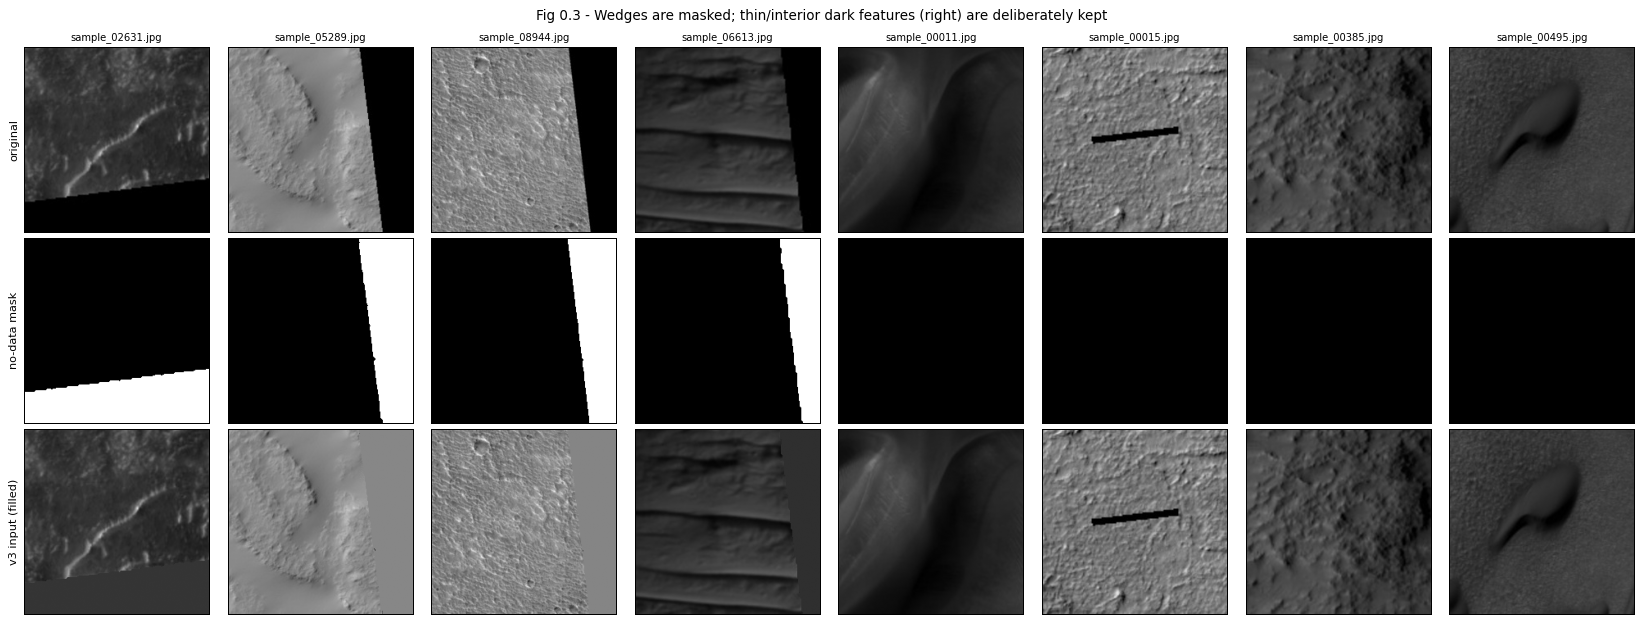

In [9]:
M = compute_nodata_masks(X, cache_path=os.path.join(CACHE, "nodata_masks.npy"))
Xf = fill_nodata(X, M)
BASE = {v: CONFIGS[v].get("residual_of", v) for v in VERSIONS}   # image-space (stage-1) model of each version
# model input per version (the stage-1 input for two-stage versions), via the same preprocess() used in training
INPUT = {v: preprocess(CONFIGS[BASE[v]], X, mask_cache=os.path.join(CACHE, "nodata_masks.npy")) for v in VERSIONS}
has_mask = M.reshape(len(M), -1).any(1)
near_black = (flat <= 5).mean(1)
print(f"crops with a masked no-data wedge: {has_mask.mean():.1%} (mean masked share {M[has_mask].mean():.1%})")
print(f"crops with >1% near-black pixels that are NOT masked (interior dark features): {((near_black > .01) & ~has_mask).sum()}")
sel = list(np.random.default_rng(0).choice(np.where(M.reshape(len(M), -1).mean(1) > .05)[0], 4, replace=False))
sel += list(np.where((near_black > .01) & ~has_mask)[0][:4])
fig, ax = plt.subplots(3, len(sel), figsize=(2.3 * len(sel), 7))
for j, i in enumerate(sel):
    ax[0, j].imshow(X[i], cmap="gray", vmin=0, vmax=255); ax[0, j].set_title(crop_index.filename[i], fontsize=8)
    ax[1, j].imshow(M[i], cmap="gray", vmin=0, vmax=1); ax[2, j].imshow(Xf[i], cmap="gray", vmin=0, vmax=255)
ax[0, 0].set_ylabel("original"); ax[1, 0].set_ylabel("no-data mask"); ax[2, 0].set_ylabel("v3 input (filled)")
for a in ax.ravel(): a.set_xticks([]); a.set_yticks([])
plt.suptitle("Fig 0.3 - Wedges are masked; thin/interior dark features (right) are deliberately kept"); plt.tight_layout()
savefig("fig02b_nodata_masks.png"); plt.show()

# Phase 1 - Deep Latent Compression (Autoencoders)

## 1.1 Architecture Design

**Design.** A convolutional autoencoder written from scratch in PyTorch (no pretrained weights,
no transfer learning).

* **Encoder:** five stride-2 3×3 convolutions (32→64→128→256→256 channels), BatchNorm + LeakyReLU.
  227 → 114 → 57 → 29 → 15 → 8. Five halvings are the minimum that brings the map to 8×8, so the
  deepest units have a receptive field covering a large part of the crop (whole craters, dune trains)
  before the bottleneck.
* **Stage-1 bottleneck (v3, reused unchanged as stage 1 of the final model v6):** flatten (256×8×8 = 16,384) → `Linear` → **fixed-length 1-D
  latent vector of 256 floats** (the Phase 2 input). The global linear layer lets every latent
  coordinate combine evidence from the whole crop, so the code describes *what kind of scene* this
  is (terrain type, texture class, relief).
* **Alternative tried and rejected (v4):** a *spatial* bottleneck, a 1×1 convolution to an 8×8
  grid × 4 channels flattened to the same 256-d vector. The aim was to keep small local defects
  visible, but each coordinate then mostly encoded *local brightness*, so the Isolation Forest
  isolated very bright or dark scenes instead of anomalies (see changelog). We therefore kept the
  global code.
* **Final model (v6): two-stage autoencoder.** A second autoencoder of the same design, with a
  64-float bottleneck, is trained on stage 1's amplified signed reconstruction residual,
  128 + 127·clip(4·(x − x̂), −1, 1). The final latent is the **fixed-length 1-D vector
  [256-d scene code | 64-d residual code] = 320 floats**. The scene code says *what kind of terrain*
  the crop is; the residual code says *what the scene code could not explain*, which is where splices,
  glitches and foreign content live. Both stages are trained from scratch on the competition crops only.
* **Decoder:** mirror image: `Linear` (v4: 1×1 conv) back to the 8×8×256 map → five ×2
  transposed-conv stages to 256×256, centre-crop to 227×227, sigmoid. Cropping (rather than odd
  output-padding) keeps every stage a clean ×2.
* Stride-2 convolutions replace pooling so the network learns its own downsampling.
* The bottleneck type, latent size, loss and no-data handling are configurable because they change
  across v1 → v4 (`CONFIGS`).

In [10]:
# ---- nssc_core.py :: model
def enc_block(cin, cout):
    return nn.Sequential(nn.Conv2d(cin, cout, 3, 2, 1, bias=False),
                         nn.BatchNorm2d(cout), nn.LeakyReLU(0.2, inplace=True))


def dec_block(cin, cout, up):
    if up == "transpose":
        layer = nn.ConvTranspose2d(cin, cout, 4, 2, 1, bias=False)
    else:  # nearest-neighbour upsample + conv: avoids checkerboard artefacts
        layer = nn.Sequential(nn.Upsample(scale_factor=2, mode="nearest"),
                              nn.Conv2d(cin, cout, 3, 1, 1, bias=False))
    return nn.Sequential(layer, nn.BatchNorm2d(cout), nn.LeakyReLU(0.2, inplace=True))


class ResBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.body = nn.Sequential(nn.Conv2d(c, c, 3, 1, 1, bias=False), nn.BatchNorm2d(c),
                                  nn.LeakyReLU(0.2, inplace=True),
                                  nn.Conv2d(c, c, 3, 1, 1, bias=False), nn.BatchNorm2d(c))

    def forward(self, x):
        return F.leaky_relu(x + self.body(x), 0.2)


class ConvAE(nn.Module):
    """Convolutional (optionally variational) autoencoder for 1x227x227 crops.

    Encoder: 5 stride-2 convs, 227 -> 114 -> 57 -> 29 -> 15 -> 8, then a linear
    bottleneck to a 1-D latent vector of size `latent_dim`.
    Decoder: linear -> 8x8 feature map, 5 x2 upsampling stages -> 256x256,
    centre-cropped back to 227x227, sigmoid output in [0, 1].
    """

    def __init__(self, latent_dim=256, chans=(32, 64, 128, 256, 256), up="transpose",
                 res_blocks=0, variational=False, spatial_latent=0):
        super().__init__()
        self.latent_dim, self.variational = latent_dim, variational
        enc, c_prev = [], 1
        for c in chans:
            enc.append(enc_block(c_prev, c))
            enc += [ResBlock(c) for _ in range(res_blocks)]
            c_prev = c
        self.encoder = nn.Sequential(*enc)
        self.c_last = chans[-1]
        flat = self.c_last * 8 * 8
        self.spatial_latent = spatial_latent
        if spatial_latent:
            # v4: 1x1-conv bottleneck -> 8x8 grid x C channels, flattened to a 1-D vector of 64*C.
            # Each cell summarises a ~63 px receptive field, so a local defect moves a few
            # coordinates strongly instead of being averaged away by a global linear layer.
            self.latent_dim = 64 * spatial_latent
            self.fc_mu = nn.Conv2d(self.c_last, spatial_latent, 1)
            self.fc_logvar = nn.Conv2d(self.c_last, spatial_latent, 1) if variational else None
            self.fc_dec = nn.Conv2d(spatial_latent, self.c_last, 1)
        else:
            self.fc_mu = nn.Linear(flat, latent_dim)
            self.fc_logvar = nn.Linear(flat, latent_dim) if variational else None
            self.fc_dec = nn.Linear(latent_dim, flat)
        dec, rev = [], list(chans[::-1]) + [16]
        for i in range(len(chans)):
            dec += [ResBlock(rev[i]) for _ in range(res_blocks)]
            dec.append(dec_block(rev[i], rev[i + 1], up))
        self.decoder = nn.Sequential(*dec)
        self.head = nn.Conv2d(16, 1, 3, 1, 1)

    def encode(self, x):
        h = self.encoder(x)
        if not self.spatial_latent:
            h = h.flatten(1)
        mu = self.fc_mu(h).flatten(1)                         # always a 1-D vector per image
        logvar = self.fc_logvar(h).flatten(1).clamp(-10, 10) if self.variational else None
        return mu, logvar

    def decode(self, z):
        if self.spatial_latent:
            h = self.fc_dec(z.view(-1, self.spatial_latent, 8, 8))
        else:
            h = self.fc_dec(z).view(-1, self.c_last, 8, 8)
        out = self.head(self.decoder(h))              # 256 x 256
        o = (out.shape[-1] - IMG_SIZE) // 2
        return torch.sigmoid(out[..., o:o + IMG_SIZE, o:o + IMG_SIZE])

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu
        if self.variational and self.training:
            z = mu + torch.randn_like(mu) * torch.exp(0.5 * logvar)
        return self.decode(z), mu, logvar

In [11]:
m = ConvAE(**CONFIGS[FINAL]["model"])
h, rows = torch.zeros(1, 1, IMG_SIZE, IMG_SIZE), []
for blk in m.encoder:
    h = blk(h); rows.append(("encoder", type(blk).__name__, tuple(h.shape[1:])))
rows.append(("bottleneck", f"1x1 Conv -> 8x8x{m.spatial_latent}, flatten" if m.spatial_latent else "Linear", (m.latent_dim,)))
print(pd.DataFrame(rows, columns=["part", "block", "output shape"]).to_string())
print(f"latent: 1-D vector of {m.latent_dim} floats | parameters: {sum(p.numel() for p in m.parameters())/1e6:.2f} M")

         part       block    output shape
0     encoder  Sequential  (32, 114, 114)
1     encoder  Sequential    (64, 57, 57)
2     encoder  Sequential   (128, 29, 29)
3     encoder  Sequential   (256, 15, 15)
4     encoder  Sequential     (256, 8, 8)
5  bottleneck      Linear           (64,)
latent: 1-D vector of 64 floats | parameters: 4.84 M


### 1.1.1 Latent dimensionality: fidelity vs separability sweep

The latent size trades **reconstruction fidelity** (a larger code keeps more detail) against
**outlier separability**. An Isolation Forest splits on randomly chosen coordinates. If many latent
dimensions carry redundant or near-constant information, most random splits are wasted and the
isolation depth of true outliers gets diluted. We trained the stage-1 configuration (the scene code of the final model) with d ∈ {64, 128,
256, 512} (short schedule) and measured three things:

* held-out SSIM (fidelity)
* the number of principal components needed for 90 % of latent variance (how much of the code is used)
* a label-free separability proxy: the *tail ratio* (99.9th-percentile Novelty Score − median) / MAD.
  This measures how far the most isolated crops sit from the bulk, in robust units.

  version  latent_dim  epochs  val_mse  val_ssim  pca90  tail_ratio  n_flag_mad35  corr_nov_nodata  flagged_with_nodata
 sweep_64          64      12 0.002692  0.682166     30   10.886942           868         0.033948             0.341014
sweep_128         128      12 0.002884  0.678145      8    9.513019           641         0.060344             0.386895
sweep_256         256      12 0.002327  0.692034     85   11.048981           828         0.069250             0.375604
sweep_512         512      12 0.002278  0.696118    109   10.494485           687         0.084176             0.394469


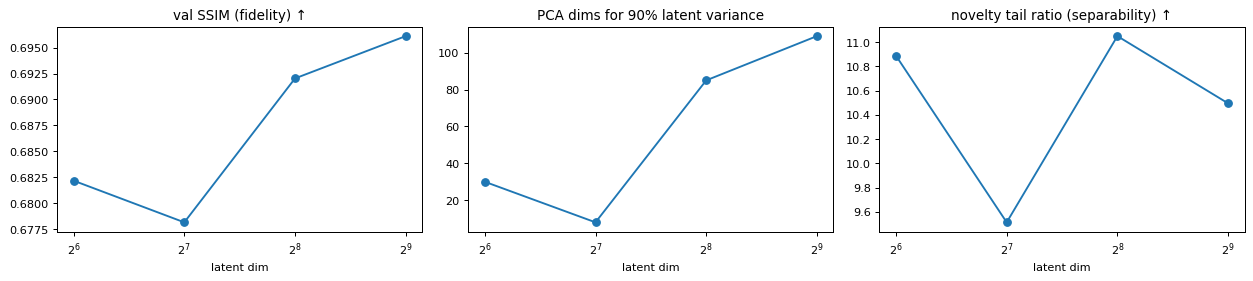

In [12]:
sweep_path = os.path.join(OUT, "latent_sweep.csv")
summ = sorted(glob.glob(os.path.join(OUT, "sweep_*", "summary.json")))
if summ:   # written by run_version.py for the final config with d in {64,128,256,512}, 12-epoch schedule
    pd.DataFrame([json.load(open(p)) for p in summ]).sort_values("latent_dim").to_csv(sweep_path, index=False)
if os.path.exists(sweep_path):
    sweep = pd.read_csv(sweep_path); print(sweep.to_string(index=False))
    fig, ax = plt.subplots(1, 3, figsize=(14, 3.2))
    ax[0].plot(sweep.latent_dim, sweep.val_ssim, "o-"); ax[0].set_title("val SSIM (fidelity) ↑")
    ax[1].plot(sweep.latent_dim, sweep.pca90, "o-"); ax[1].set_title("PCA dims for 90% latent variance")
    ax[2].plot(sweep.latent_dim, sweep.tail_ratio, "o-"); ax[2].set_title("novelty tail ratio (separability) ↑")
    for a in ax: a.set_xscale("log", base=2); a.set_xlabel("latent dim")
    plt.tight_layout(); savefig("fig03_latent_sweep.png"); plt.show()

**Choice: d = 256.** The sweep uses a short 12-epoch schedule and a single seed, so its flagged
counts are not comparable with the fully trained model and are shown only for completeness. The
differences are indicative, not conclusive.

* **Fidelity saturates.** Held-out SSIM is 0.682 (64), 0.678 (128), 0.692 (256) and 0.696 (512).
  Doubling from 256 to 512 buys only +0.004.
* **Effective dimensionality grows sub-linearly.** 30, 8, 85 and 109 principal components hold 90 %
  of the latent variance. Going to 512 adds 256 coordinates but only about 24 effective directions.
  The rest are redundant, and redundant coordinates **dilute an Isolation Forest**, whose splits pick
  a coordinate uniformly at random.
* **The separability proxy is flat.** The tail ratio is 10.9, 9.5, 11.0 and 10.5, too close to rank the
  candidates; it also rewards nuisance modes (the rejected v2 scores 14.7), so it is only a sanity check. The correlation with the
  no-data fraction (the nuisance removed in v3) creeps up with size (0.03 → 0.08), because a bigger
  code has room to re-encode fill geometry.
* **d = 128 is an outlier.** 90 % of its variance sits in only 8 components, a partial collapse
  under the short schedule, and it has the weakest tail.

We therefore choose 256 on fidelity and effective dimensionality: it is the smallest code at which
reconstruction fidelity is essentially saturated without adding largely redundant coordinates.

## 1.2 Loss Function Design

**Loss design.** v1 used pure MSE. MSE is minimised by the conditional mean, so when fine texture
(dune ripples, crater rims, polygonal ground) is uncertain the decoder outputs a blurred average.
The v1 reconstructions show this clearly (Fig 1.2). From v2 on, the objective is
**0.84·(1 − SSIM) + 0.16·L1 + 0.1·Gradient-L1**, computed only on valid (non-no-data) pixels from v3 on.
Its fully differentiable terms (weights in `CONFIGS`) complement each other:

* **(1 − SSIM)** with an 11×11 Gaussian window (σ = 1.5) compares local mean, contrast and structure.
  It penalises the loss of local structure even when the average brightness is right, which directly
  targets blur on ridges and crater rims.
* **L1** anchors absolute brightness. SSIM is insensitive to uniform intensity offsets, so on
  its own it can drift in albedo.
* **Gradient L1** (finite-difference edges) penalises smeared or misplaced high-frequency edges,
  which helps sharp linear features such as ridgelines and scarps.

No perceptual loss is used, because every perceptual network we could use would be pretrained, and
that is banned.

**What the iterations taught us about this loss.** Switching from MSE (v1) to this combination (v2)
sharpened crater rims and scarps, but it did **not** recover dune-ripple texture: held-out SSIM only
went from 0.7053 to 0.7065. The binding constraint is the bottleneck, not the loss. 256 floats for
51,529 pixels cannot store the exact phase of a ripple field, and a loss cannot recreate information
the code has discarded. We keep the structural loss because it spends the unavoidable error on
texture detail rather than on structure. Its edge sensitivity, however, made the network lock onto
the razor-sharp edges of the no-data wedges (v2's novelty correlated 0.66 with the no-data share).
That is why, from v3 on, every term is computed on valid pixels only (Section 0.2).

**Stage-2 loss (v6).** The residual autoencoder reconstructs a signed residual image, not terrain, so
structural similarity is not meaningful there; it uses MSE + 0.5·L1 on valid pixels.

In [13]:
# ---- nssc_core.py :: losses
def _gauss_window(size=11, sigma=1.5, device="cpu"):
    g = torch.arange(size, dtype=torch.float32, device=device) - size // 2
    g = torch.exp(-(g ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    return (g[:, None] @ g[None, :])[None, None]


def ssim_map(x, y, window=None, C1=0.01 ** 2, C2=0.03 ** 2):
    """Differentiable per-pixel SSIM (Wang et al. 2004) for images in [0, 1]."""
    if window is None:
        window = _gauss_window(device=x.device)
    p = window.shape[-1] // 2
    mu_x, mu_y = F.conv2d(x, window, padding=p), F.conv2d(y, window, padding=p)
    sxx = F.conv2d(x * x, window, padding=p) - mu_x ** 2
    syy = F.conv2d(y * y, window, padding=p) - mu_y ** 2
    sxy = F.conv2d(x * y, window, padding=p) - mu_x * mu_y
    return ((2 * mu_x * mu_y + C1) * (2 * sxy + C2)) / ((mu_x ** 2 + mu_y ** 2 + C1) * (sxx + syy + C2))


def _wmean(t, w):
    """Mean of t over pixels, weighted by validity map w (None = plain mean)."""
    return t.mean() if w is None else (t * w).sum() / w.sum().clamp_min(1.0)


def gradient_loss(x, y, w=None):
    """L1 distance between horizontal/vertical finite differences (edge fidelity)."""
    dx = lambda t: t[..., :, 1:] - t[..., :, :-1]
    dy = lambda t: t[..., 1:, :] - t[..., :-1, :]
    wx = None if w is None else w[..., :, 1:] * w[..., :, :-1]
    wy = None if w is None else w[..., 1:, :] * w[..., :-1, :]
    return _wmean((dx(x) - dx(y)).abs(), wx) + _wmean((dy(x) - dy(y)).abs(), wy)


class ReconLoss(nn.Module):
    """w_mse*MSE + w_l1*L1 + w_ssim*(1-SSIM) + w_grad*GradL1 (+ beta*KL for a VAE).

    Optional validity map w (1 = real terrain, 0 = no-data) restricts every term to valid pixels.
    """

    def __init__(self, w_mse=1.0, w_l1=0.0, w_ssim=0.0, w_grad=0.0, beta_kl=0.0):
        super().__init__()
        self.w = dict(mse=w_mse, l1=w_l1, ssim=w_ssim, grad=w_grad)
        self.beta_kl = beta_kl
        self.register_buffer("window", _gauss_window())

    def forward(self, xhat, x, mu=None, logvar=None, w=None):
        terms = {}
        if self.w["mse"]: terms["mse"] = _wmean((xhat - x) ** 2, w)
        if self.w["l1"]: terms["l1"] = _wmean((xhat - x).abs(), w)
        if self.w["ssim"]: terms["ssim"] = 1 - _wmean(ssim_map(xhat, x, self.window), w)
        if self.w["grad"]: terms["grad"] = gradient_loss(xhat, x, w)
        total = sum(self.w[k] * v for k, v in terms.items())
        if self.beta_kl and logvar is not None:
            kl = -0.5 * torch.mean(torch.sum(1 + logvar - mu ** 2 - logvar.exp(), 1))
            terms["kl"] = kl
            total = total + self.beta_kl * kl
        return total, {k: float(v.detach()) for k, v in terms.items()}

### 1.2.1 Training (all versions v1-v4)

In [14]:
# ---- nssc_core.py :: training
def to_batch(u8, idx, augment=False, mask_u8=None):
    """uint8 GPU tensor [N,H,W] -> float [B,1,H,W] in [0,1] (+ validity map), optional random flips."""
    x = u8[idx].float().div_(255.0).unsqueeze(1)
    w = None if mask_u8 is None else (1.0 - mask_u8[idx].float()).unsqueeze(1)
    if augment:
        B = x.shape[0]
        fh = (torch.rand(B, device=x.device) < 0.5)[:, None, None, None]
        fv = (torch.rand(B, device=x.device) < 0.5)[:, None, None, None]
        flip = lambda t: torch.where(fv, torch.where(fh, t.flip(-1), t).flip(-2), torch.where(fh, t.flip(-1), t))
        x = flip(x)
        w = None if w is None else flip(w)
    return x, w


def train_autoencoder(model, images_u8, loss_fn, epochs=30, batch_size=64, lr=1e-3,
                      val_frac=0.1, augment=True, seed=42, log_every=1, sample_weights=None,
                      masks_u8=None):
    """Train on all crops (unlabelled) with a random 10% split held out for loss curves.

    masks_u8: optional no-data masks (1 = no-data); those pixels are excluded from the loss.
    sample_weights: optional per-image sampling weights.
    """
    seed_everything(seed)
    model = model.to(DEVICE)
    loss_fn = loss_fn.to(DEVICE)
    X = torch.from_numpy(images_u8).to(DEVICE)
    M = None if masks_u8 is None else torch.from_numpy(masks_u8).to(DEVICE)
    N = len(X)
    perm = np.random.permutation(N)
    n_val = int(N * val_frac)
    val_idx, tr_idx = perm[:n_val], perm[n_val:]
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-5)
    steps = math.ceil(len(tr_idx) / batch_size)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * steps, pct_start=0.1)
    hist = []
    for ep in range(epochs):
        t0 = time.time()
        model.train()
        if sample_weights is not None:
            p = sample_weights[tr_idx] / sample_weights[tr_idx].sum()
            order = np.random.choice(tr_idx, size=len(tr_idx), replace=True, p=p)
        else:
            order = np.random.permutation(tr_idx)
        run, parts_sum = 0.0, {}
        for s in range(steps):
            idx = torch.from_numpy(order[s * batch_size:(s + 1) * batch_size]).to(DEVICE)
            x, w = to_batch(X, idx, augment, M)
            with torch.autocast("cuda", dtype=torch.bfloat16, enabled=USE_BF16):
                xhat, mu, logvar = model(x)
            loss, parts = loss_fn(xhat.float(), x, mu.float(), None if logvar is None else logvar.float(), w)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step(); sched.step()
            run += loss.item()
            for k, v in parts.items(): parts_sum[k] = parts_sum.get(k, 0) + v
        val = evaluate_recon(model, X, val_idx, M)
        rec = dict(epoch=ep + 1, train_loss=run / steps, **{f"train_{k}": v / steps for k, v in parts_sum.items()},
                   val_mse=val["mse"], val_ssim=val["ssim"], sec=time.time() - t0)
        hist.append(rec)
        if (ep + 1) % log_every == 0:
            print(f"ep {ep+1:3d}/{epochs} loss {rec['train_loss']:.4f} | val MSE {val['mse']:.5f} "
                  f"SSIM {val['ssim']:.4f} | {rec['sec']:.1f}s")
    return model, pd.DataFrame(hist), val_idx


@torch.no_grad()
def _batch_metrics(model, X, idx, M, window):
    x, w = to_batch(X, idx, False, M)
    xhat, mu, _ = model(x)
    xhat = xhat.float()
    if w is None:
        w = torch.ones_like(x)
    den = w.sum(dim=(1, 2, 3)).clamp_min(1.0)
    mse = (((xhat - x) ** 2) * w).sum(dim=(1, 2, 3)) / den
    ssim = (ssim_map(xhat, x, window) * w).sum(dim=(1, 2, 3)) / den
    return mu.float(), mse, ssim


@torch.no_grad()
def evaluate_recon(model, X, idx, M=None, batch_size=128):
    """Mean per-image MSE / SSIM over idx, computed on valid (non-no-data) pixels if M is given."""
    model.eval()
    window = _gauss_window(device=DEVICE)
    mse, ssim = [], []
    for s in range(0, len(idx), batch_size):
        b = torch.as_tensor(idx[s:s + batch_size], device=DEVICE)
        _, m_, s_ = _batch_metrics(model, X, b, M, window)
        mse.append(m_); ssim.append(s_)
    return dict(mse=torch.cat(mse).mean().item(), ssim=torch.cat(ssim).mean().item())


@torch.no_grad()
def embed_and_reconstruct(model, images_u8, masks_u8=None, batch_size=128):
    """Latent vectors (mu) for every crop, plus per-image reconstruction MSE / SSIM (valid pixels)."""
    model.eval().to(DEVICE)
    X = torch.from_numpy(images_u8).to(DEVICE)
    M = None if masks_u8 is None else torch.from_numpy(masks_u8).to(DEVICE)
    window = _gauss_window(device=DEVICE)
    Z, mse, ssim = [], [], []
    for s in range(0, len(X), batch_size):
        idx = torch.arange(s, min(s + batch_size, len(X)), device=DEVICE)
        z, m_, s_ = _batch_metrics(model, X, idx, M, window)
        Z.append(z.cpu().numpy()); mse.append(m_.cpu().numpy()); ssim.append(s_.cpu().numpy())
    return np.concatenate(Z), np.concatenate(mse), np.concatenate(ssim)


@torch.no_grad()
def residual_images(model, images_u8, masks_u8=None, gain=4.0, batch_size=128):
    """Stage-2 input of the two-stage autoencoder: the signed reconstruction residual of a trained
    stage-1 model, amplified and mapped to uint8 as 128 + 127*clip(gain*(x - x_hat), -1, 1).
    No-data pixels are set to 128 (zero residual)."""
    model.eval().to(DEVICE)
    X = torch.from_numpy(images_u8).to(DEVICE)
    M = None if masks_u8 is None else torch.from_numpy(masks_u8).to(DEVICE)
    out = np.empty_like(images_u8)
    for s in range(0, len(X), batch_size):
        idx = torch.arange(s, min(s + batch_size, len(X)), device=DEVICE)
        x, w = to_batch(X, idx, False, M)
        r = x - model(x)[0].float()
        if w is not None:
            r = r * w
        out[s:s + len(idx)] = (128 + 127 * (gain * r).clamp(-1, 1)).round().squeeze(1).byte().cpu().numpy()
    return out


def load_model(v, out_dir):
    m = ConvAE(**CONFIGS[v]["model"])
    m.load_state_dict(torch.load(os.path.join(out_dir, v, "model.pt"), map_location=DEVICE))
    return m.to(DEVICE).eval()


def version_latents(v, X, out_dir, mask_cache=None):
    """Final fixed-length 1-D latent per crop for version v, plus the stage-1 reconstruction
    MSE / SSIM. Two-stage versions (residual_of=...) concatenate the stage-1 scene code with the
    stage-2 code of the stage-1 reconstruction residual."""
    cfg = CONFIGS[v]
    if cfg.get("residual_of"):
        base = cfg["residual_of"]
        Xin, M = preprocess(CONFIGS[base], X, mask_cache)       # stage 1 sees exactly its own input
        s1 = load_model(base, out_dir)
        Z1, mse, ssim = embed_and_reconstruct(s1, Xin, M)
        Z2, _, _ = embed_and_reconstruct(load_model(v, out_dir), residual_images(s1, Xin, M), M)
        return np.hstack([Z1, Z2]), mse, ssim
    Xin, M = preprocess(cfg, X, mask_cache)
    return embed_and_reconstruct(load_model(v, out_dir), Xin, M)


@torch.no_grad()
def reconstruct(model, images_u8, indices):
    model.eval().to(DEVICE)
    x = torch.from_numpy(images_u8[indices]).to(DEVICE).float().div(255).unsqueeze(1)
    return x.squeeze(1).cpu().numpy(), model(x)[0].float().squeeze(1).cpu().numpy()

In [15]:
def train_or_load(v):
    """Train version v (or load its checkpoint produced by exactly this code)."""
    cfg, out = CONFIGS[v], os.path.join(OUT, v)
    seed_everything(42)   # identical initial weights on every run
    model = ConvAE(**cfg["model"])
    if RETRAIN or not os.path.exists(os.path.join(out, "model.pt")):
        os.makedirs(out, exist_ok=True)
        Xin, Min = INPUT[v]
        if cfg.get("residual_of"):   # two-stage: stage 2 learns the stage-1 reconstruction residual
            Xin = residual_images(R[cfg["residual_of"]]["model"], Xin, Min)
        model, hist, _ = train_autoencoder(model, Xin, ReconLoss(**cfg["loss"]), epochs=cfg["epochs"],
                                           lr=cfg["lr"], masks_u8=Min)
        torch.save(model.state_dict(), os.path.join(out, "model.pt")); hist.to_csv(os.path.join(out, "history.csv"), index=False)
    model.load_state_dict(torch.load(os.path.join(out, "model.pt"), map_location=DEVICE))
    return model.to(DEVICE).eval(), pd.read_csv(os.path.join(out, "history.csv"))

R = {}
for v in VERSIONS:
    model, hist = train_or_load(v)
    # final fixed-length 1-D latent (two-stage versions: [stage-1 scene code | stage-2 residual code]);
    # mse/ssim are the stage-1 (image-space) reconstruction errors on valid pixels
    Z, mse, ssim = version_latents(v, X, OUT, mask_cache=os.path.join(CACHE, "nodata_masks.npy"))
    two = BASE[v] != v
    R[v] = dict(model=R[BASE[v]]["model"] if two else model, stage2=model if two else None,
                hist=R[BASE[v]]["hist"] if two else hist, Z=Z, mse=mse, ssim=ssim)
    print(f"{v}: final val MSE {hist.val_mse.iloc[-1]:.5f} | val SSIM {hist.val_ssim.iloc[-1]:.4f} | "
          f"epochs {len(hist)} | {hist.sec.sum()/60:.1f} min")

v1: final val MSE 0.00189 | val SSIM 0.7053 | epochs 30 | 5.6 min


v2: final val MSE 0.00228 | val SSIM 0.7065 | epochs 30 | 8.2 min


v3: final val MSE 0.00214 | val SSIM 0.7195 | epochs 30 | 8.1 min


v4: final val MSE 0.00218 | val SSIM 0.7159 | epochs 30 | 6.7 min


v5: final val MSE 0.01001 | val SSIM 0.5308 | epochs 30 | 8.1 min


v6: final val MSE 0.00711 | val SSIM 0.4793 | epochs 30 | 5.5 min


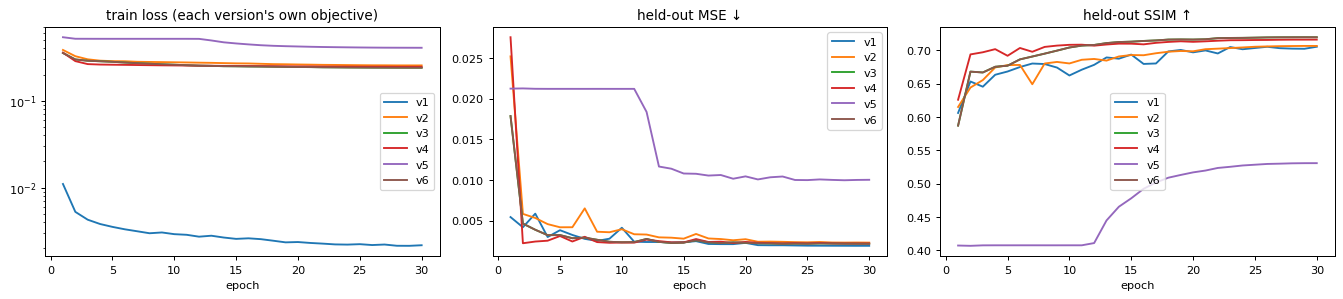

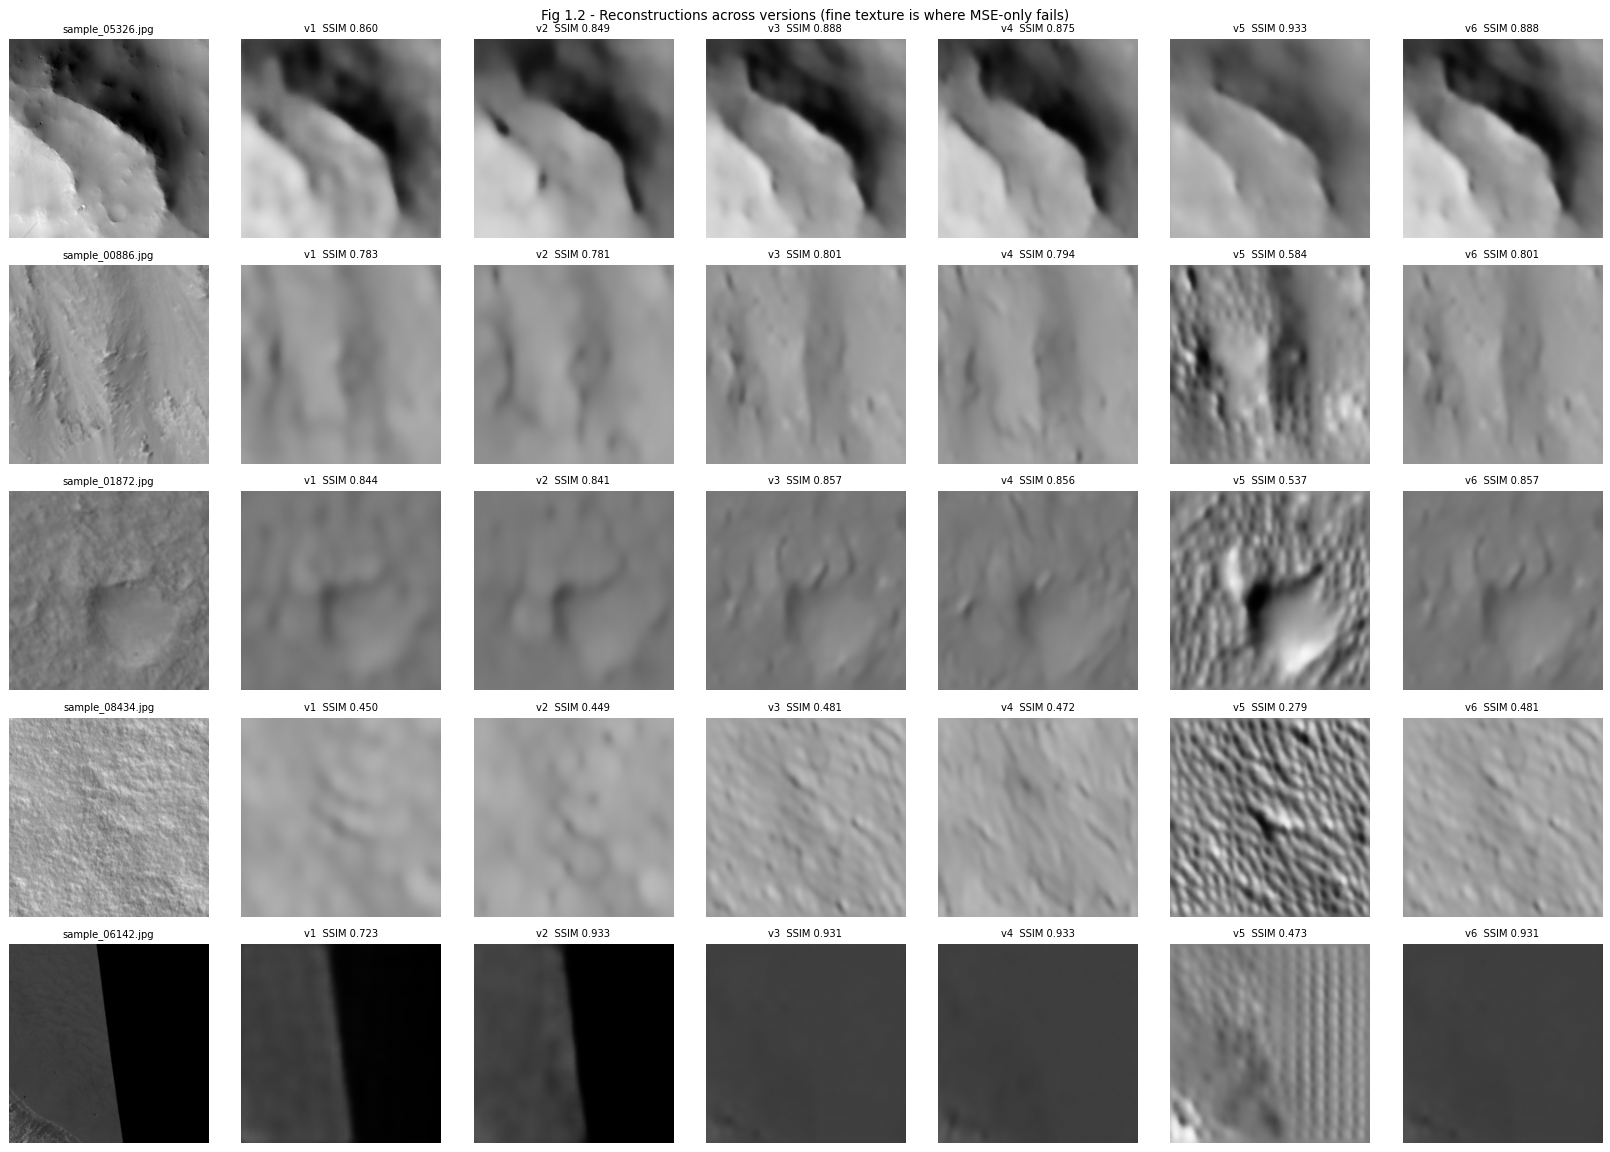

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.4))
for v in VERSIONS:
    h = R[v]["hist"]
    ax[0].plot(h.epoch, h.train_loss, label=v); ax[1].plot(h.epoch, h.val_mse, label=v); ax[2].plot(h.epoch, h.val_ssim, label=v)
ax[0].set_title("train loss (each version's own objective)"); ax[0].set_yscale("log")
ax[1].set_title("held-out MSE ↓"); ax[2].set_title("held-out SSIM ↑")
for a in ax: a.legend(); a.set_xlabel("epoch")
plt.tight_layout(); savefig("fig04_training_curves.png"); plt.show()

show = [int(np.argmax(img_std * (nodata < .01)))]   # highest-texture crop without no-data
rng = np.random.default_rng(3); show += list(rng.choice(np.where(nodata < .01)[0], 3, replace=False)); show += [int(np.argmax(nodata))]
fig, ax = plt.subplots(len(show), 1 + len(VERSIONS), figsize=(2.6 * (1 + len(VERSIONS)), 2.6 * len(show)))
for r_, i in enumerate(show):
    ax[r_, 0].imshow(X[i], cmap="gray", vmin=0, vmax=255); ax[r_, 0].set_title(crop_index.filename[i], fontsize=8)
    for c_, v in enumerate(VERSIONS):
        _, rec = reconstruct(R[v]["model"], INPUT[v][0], [i])
        ax[r_, c_ + 1].imshow(rec[0], cmap="gray", vmin=0, vmax=1)
        ax[r_, c_ + 1].set_title(f"{v}  SSIM {R[v]['ssim'][i]:.3f}", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Fig 1.2 - Reconstructions across versions (fine texture is where MSE-only fails)"); plt.tight_layout()
savefig("fig05_recon_versions.png"); plt.show()

## 1.3 Latent Space Visualisation

PCA (50 components on standardised latents) followed by t-SNE (perplexity 40). Colouring by simple
image properties the model never saw as labels shows *which* factors of variation the latent space
organises. This is a qualitative diagnostic only, not proof of geological clusters.

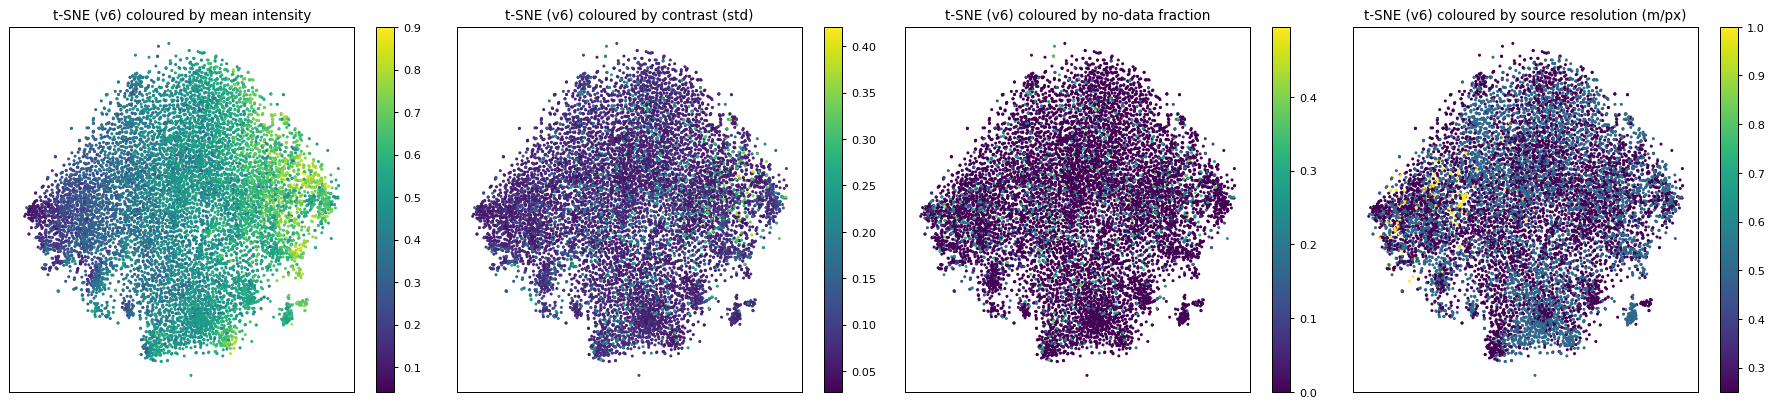

In [17]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
def tsne_embed(Z, seed=0):
    Zp = PCA(50, random_state=seed).fit_transform((Z - Z.mean(0)) / (Z.std(0) + 1e-8))
    return TSNE(2, perplexity=40, init="pca", random_state=seed).fit_transform(Zp)
tsne_path = os.path.join(OUT, FINAL, "tsne.npy")
E = np.load(tsne_path) if (os.path.exists(tsne_path) and not RETRAIN) else tsne_embed(R[FINAL]["Z"])
np.save(tsne_path, E)
res = crop_index.source_image_id.map(source_meta.set_index("source_image_id").resolution).values
fig, ax = plt.subplots(1, 4, figsize=(20, 4.6))
for a, c, t in [(ax[0], img_mean, "mean intensity"), (ax[1], img_std, "contrast (std)"),
                (ax[2], nodata, "no-data fraction"), (ax[3], res, "source resolution (m/px)")]:
    sc = a.scatter(E[:, 0], E[:, 1], c=c, s=2, cmap="viridis"); plt.colorbar(sc, ax=a); a.set_title(f"t-SNE ({FINAL}) coloured by {t}")
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig("fig06_tsne_properties.png"); plt.show()

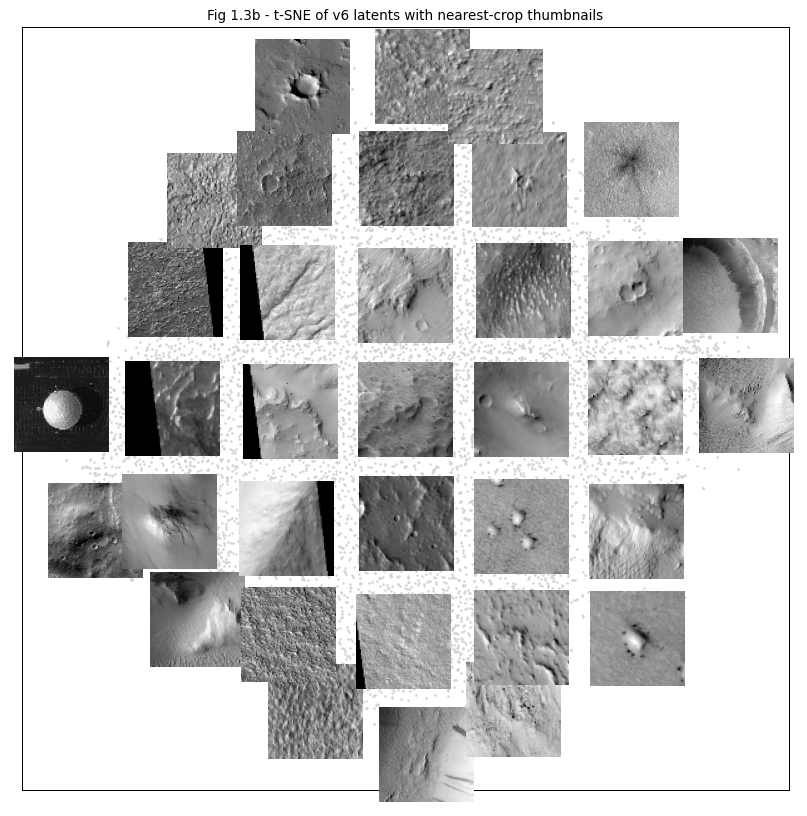

In [18]:
# thumbnails sampled across the map to show what each region contains (visual interpretation only)
fig, ax = plt.subplots(figsize=(11, 11)); ax.scatter(E[:, 0], E[:, 1], s=1, c="lightgray")
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
gx = np.linspace(E[:, 0].min(), E[:, 0].max(), 7); gy = np.linspace(E[:, 1].min(), E[:, 1].max(), 7)
for x_ in gx:
    for y_ in gy:
        d = np.hypot(E[:, 0] - x_, E[:, 1] - y_); i = int(np.argmin(d))
        if d[i] < (gx[1] - gx[0]) * 0.4:
            ax.add_artist(AnnotationBbox(OffsetImage(X[i][::3, ::3], cmap="gray", zoom=1.0), E[i], frameon=False))
ax.set_title(f"Fig 1.3b - t-SNE of {FINAL} latents with nearest-crop thumbnails"); ax.set_xticks([]); ax.set_yticks([])
savefig("fig07_tsne_thumbs.png"); plt.show()

**Reading the map (visual interpretation, not labels).**

* **No collapse.** The projection is not one structureless blob. It has a dense core, extended arms and
  several small isolated islands.
* **Brightness is the dominant organising axis.** Mean intensity changes smoothly from one side of the
  map to the other; contrast varies more locally.
* **Pixel scale is encoded too.** Crops from the single 1 m/px observation concentrate in one compact
  region, and 0.5 m/px crops are over-represented in parts of the map. The same terrain imaged at a
  coarser scale has a different texture frequency.
* **The no-data fraction is spread uniformly.** This is visual confirmation that masking removed the
  border nuisance that dominated v1 and v2.
* The thumbnails show coherent neighbourhoods rather than discrete clusters (knobby and rough terrain,
  cratered plains, ripples and dunes, bright etched or polygonal ground, smooth dusty slopes): a
  continuum of terrain types.
* After thresholding (Fig 1.3c, produced in Section 2.2), flagged crops lie mainly on the **periphery
  of the map and in its outer lobes**, with only a few in the interior, as expected if the Isolation
  Forest isolates sparse regions.

# Phase 2 - Isolation Forest Novelty Engine

## 2.1 Novelty Scoring

The Isolation Forest is fitted on the 1-D latent vectors of **all** crops (unsupervised: there is no
"clean" training set). We use 500 trees and 256-sample sub-sampling (the original paper's
recommended ψ), and average 5 forests with different seeds to reduce the variance of the ranking.

**Score convention.** sklearn's `score_samples` returns the *negated* anomaly score (higher = more
normal). We negate it, so our **Novelty Score = s(x, n) ∈ (0, 1] from Liu et al. (2008), and higher
= more anomalous**. This is the competition convention, and it is verified below by the sign of the
correlation with sklearn's `decision_function`.

In [19]:
# ---- nssc_core.py :: iforest
from sklearn.ensemble import IsolationForest


def novelty_scores(Z, n_estimators=500, max_samples=256, seeds=(0, 1, 2, 3, 4)):
    """Isolation Forest novelty score, averaged over seeds for stability.

    sklearn's score_samples() returns the *negated* anomaly score of Liu et al.
    (2008), i.e. higher = more normal. We negate it back, so the returned
    Novelty Score equals s(x, n) in (0, 1]: HIGHER = MORE ANOMALOUS, which is the
    competition convention. contamination='auto' only affects sklearn's
    predict() labels, which we never use: the anomaly count comes from the
    statistical threshold on these continuous scores.
    """
    runs = []
    for s in seeds:
        forest = IsolationForest(n_estimators=n_estimators, max_samples=max_samples,
                                 contamination="auto", random_state=s, n_jobs=-1).fit(Z)
        runs.append(-forest.score_samples(Z))
    runs = np.stack(runs)
    return runs.mean(0), runs.std(0)

In [20]:
for v in VERSIONS:
    p = os.path.join(OUT, v, "novelty.npy")
    if os.path.exists(p) and not RETRAIN: R[v]["nov"] = np.load(p)
    else: R[v]["nov"] = novelty_scores(R[v]["Z"])[0]; np.save(p, R[v]["nov"])
nov = R[FINAL]["nov"]
# convention check: our score must be anti-correlated with sklearn's decision_function (higher = more normal)
chk = IsolationForest(n_estimators=200, random_state=0).fit(R[FINAL]["Z"])
print("corr(novelty, sklearn decision_function) =", round(np.corrcoef(nov, chk.decision_function(R[FINAL]["Z"]))[0, 1], 3), "(must be strongly negative)")
# seed stability of the ranking
runs = [ -IsolationForest(n_estimators=500, max_samples=256, random_state=s, n_jobs=-1).fit(R[FINAL]["Z"]).score_samples(R[FINAL]["Z"]) for s in (10, 11)]
print("Spearman rank corr between two independent forests:", round(pd.Series(runs[0]).corr(pd.Series(runs[1]), method="spearman"), 4))
print("Spearman(novelty, reconstruction MSE):", round(pd.Series(nov).corr(pd.Series(R[FINAL]["mse"]), method="spearman"), 3))

corr(novelty, sklearn decision_function) = -0.98 (must be strongly negative)


Spearman rank corr between two independent forests: 0.9814
Spearman(novelty, reconstruction MSE): 0.569


## 2.2 Statistical Thresholding

We want the boundary to come from the **shape of the observed score distribution**, not from an
assumed count. First we test whether a Gaussian μ + kσ rule is even appropriate (skewness, kurtosis,
D'Agostino K² test, Q-Q plot). Then we compare three distribution-driven rules:

1. **Robust modified z-score** (Iglewicz & Hoaglin 1993): M = 0.6745 (s − median) / MAD, flag
   M > 3.5. Median and MAD have a 50 % breakdown point, so the outliers being hunted cannot inflate
   the threshold. Under normality 0.6745 × MAD estimates σ, so 3.5 is comparable to ≈3.5σ.
2. **Kneedle elbow** of the ascending sorted-score curve: min-max normalise both axes and take the
   point of maximum vertical distance below the chord joining the end points. This is the point of
   maximum curvature, where the curve turns from "bulk" to "tail".
3. **Two-component Gaussian mixture**: the score where the posterior of the high-mean component
   exceeds 0.5.

In [21]:
# ---- nssc_core.py :: threshold
def mad_threshold(scores, k=3.5):
    """Iglewicz & Hoaglin (1993) modified z-score: M = 0.6745 (x - median) / MAD, flag M > k."""
    med = np.median(scores)
    mad = np.median(np.abs(scores - med))
    return med + k * mad / 0.6745


def kneedle_threshold(scores):
    """Elbow of the ascending sorted-score curve: the point farthest from the chord joining
    the curve's endpoints after min-max normalisation (Satopaa et al. 2011, 'Kneedle')."""
    y = np.sort(scores)
    x = np.linspace(0, 1, len(y))
    yn = (y - y[0]) / (y[-1] - y[0])
    i = int(np.argmax(x - yn))       # convex increasing curve: max distance below the chord
    return y[i], i


def gmm_threshold(scores, seed=0):
    """Two-component 1-D Gaussian mixture on the scores; boundary where the posterior of the
    high-mean component first exceeds 0.5."""
    from sklearn.mixture import GaussianMixture
    g = GaussianMixture(2, random_state=seed).fit(scores.reshape(-1, 1))
    hi = int(np.argmax(g.means_.ravel()))
    grid = np.linspace(scores.min(), scores.max(), 5000).reshape(-1, 1)
    post = g.predict_proba(grid)[:, hi]
    above = np.where((post > 0.5) & (grid.ravel() > g.means_.ravel()[1 - hi]))[0]
    return float(grid[above[0], 0]) if len(above) else float("nan"), g


def distribution_diagnostics(scores):
    k2, p = stats.normaltest(scores)
    return dict(n=len(scores), mean=scores.mean(), std=scores.std(), median=np.median(scores),
                mad=np.median(np.abs(scores - np.median(scores))),
                skew=stats.skew(scores), excess_kurtosis=stats.kurtosis(scores),
                dagostino_k2=k2, normality_p=p)

In [22]:
diag = distribution_diagnostics(nov)
print(pd.Series(diag).round(5).to_string())
t_mad = mad_threshold(nov, 3.5)
t_knee, i_knee = kneedle_threshold(nov)
t_gmm, gmm = gmm_threshold(nov)
t_ms3 = nov.mean() + 3 * nov.std()
cands = pd.DataFrame([
    ("Modified z-score (median + 3.5 MAD/0.6745)", t_mad),
    ("Kneedle elbow of sorted scores", t_knee),
    ("2-component GMM posterior = 0.5", t_gmm),
    ("mu + 3 sigma (assumes Gaussian - rejected)", t_ms3)], columns=["method", "threshold"])
cands["n_flagged"] = [(nov > t).sum() for t in cands.threshold]
print(cands.to_string(index=False))

n                  10422.00000
mean                   0.42102
std                    0.03116
median                 0.41648
mad                    0.02093
skew                   0.74594
excess_kurtosis        0.64662
dagostino_k2         885.04237
normality_p            0.00000


                                    method  threshold  n_flagged
Modified z-score (median + 3.5 MAD/0.6745)   0.525080         48
            Kneedle elbow of sorted scores   0.463303        987
           2-component GMM posterior = 0.5   0.429142       3740
mu + 3 sigma (assumes Gaussian - rejected)   0.514507         82


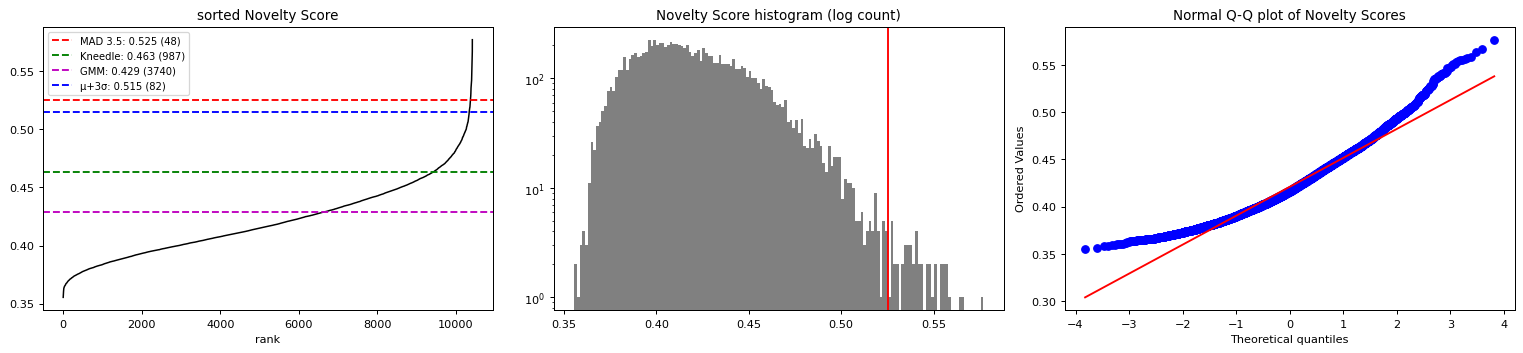

In [23]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
s_sorted = np.sort(nov)
ax[0].plot(s_sorted, lw=1.2, c="k")
for t, c, l in [(t_mad, "r", "MAD 3.5"), (t_knee, "g", "Kneedle"), (t_gmm, "m", "GMM"), (t_ms3, "b", "μ+3σ")]:
    ax[0].axhline(t, ls="--", c=c, label=f"{l}: {t:.3f} ({(nov > t).sum()})")
ax[0].set_title("sorted Novelty Score"); ax[0].set_xlabel("rank"); ax[0].legend(fontsize=8)
ax[1].hist(nov, 150, color="0.5"); ax[1].set_yscale("log"); ax[1].axvline(THRESHOLD if "THRESHOLD" in globals() else t_mad, c="r")
ax[1].set_title("Novelty Score histogram (log count)")
stats.probplot(nov, dist="norm", plot=ax[2]); ax[2].set_title("Normal Q-Q plot of Novelty Scores")
plt.tight_layout(); savefig("fig08_threshold_candidates.png"); plt.show()

### Choice: robust modified z-score > 3.5 → **threshold 0.5251, 48 crops flagged (0.46 %)**

1. **A Gaussian μ + kσ rule is not supported by the data.** The final (v6) scores have skewness 0.75,
   excess kurtosis 0.65 and D'Agostino K² = 885 (p ≈ 0), and the Q-Q plot bends upward in the right
   tail. μ and σ are also estimated *including* the tail we are trying to find, so the outliers
   inflate their own threshold. We keep μ + 3σ only as a cross-check.
2. **The elbow and GMM boundaries sit inside the body of the distribution, not at a break.** The score
   distribution is unimodal. A two-component GMM therefore splits the single skewed bulk into two
   overlapping Gaussians, and its boundary falls near the 64th percentile (3,740 crops). The Kneedle
   elbow of the *whole* sorted curve marks where the curve leaves its straight middle section, at the
   start of the ordinary right skew of normal terrain (987 crops). Neither boundary coincides with any
   change in the behaviour of the density.
3. **The modified z-score is built for exactly this situation.** Median and MAD have a 50 % breakdown
   point, so however many outliers exist they cannot move the threshold. k = 3.5 is the value
   recommended by Iglewicz & Hoaglin (1993). Under a Gaussian bulk with this robust scale about 2.4 of
   10,422 normal crops would exceed it by chance; the real bulk is right-skewed, so this is a lower
   bound, not a guarantee.
4. **Cross-checks bracket the choice.** μ + 3σ flags 82 crops, and the same robust rule applied to
   log-scores (which reduces the skew from 0.75 to 0.54) flags 22. The chosen 48 lies between the
   classical and the skew-corrected rule, and on the sorted-score plot all three sit in the final
   steep rise, where the curve turns from gradual to near-vertical.
5. **Sensitivity is reported, not tuned.** k = 3, 3.5, 4 and 5 give 97, 48, 24 and 1 flagged crops.
   We keep the conventional k = 3.5 rather than choosing k to hit a count.

In [24]:
THRESHOLD = t_mad            # final rule: robust modified z-score > 3.5 (justification above)
flagged = nov > THRESHOLD
print(f"FINAL NOVELTY THRESHOLD = {THRESHOLD:.4f}  ->  {flagged.sum()} of {len(nov)} crops flagged ({flagged.mean():.2%})")
for k in (3.0, 3.5, 4.0, 5.0):          # sensitivity of the count to the cutoff constant (reported, not tuned)
    print(f"  k = {k}: threshold {mad_threshold(nov, k):.4f} -> {(nov > mad_threshold(nov, k)).sum()} flagged")
print(f"expected chance exceedances if the bulk were Gaussian with the robust scale: {len(nov) * stats.norm.sf(3.5):.1f} crops")
lt = np.log(nov)                          # skew-robust cross-check: the same rule on log-scores
print(f"same rule on log-scores (skew {stats.skew(lt):.2f}): {(lt > mad_threshold(lt, 3.5)).sum()} flagged")

FINAL NOVELTY THRESHOLD = 0.5251  ->  48 of 10422 crops flagged (0.46%)
  k = 3.0: threshold 0.5096 -> 97 flagged
  k = 3.5: threshold 0.5251 -> 48 flagged
  k = 4.0: threshold 0.5406 -> 24 flagged
  k = 5.0: threshold 0.5716 -> 1 flagged
expected chance exceedances if the bulk were Gaussian with the robust scale: 2.4 crops
same rule on log-scores (skew 0.54): 22 flagged


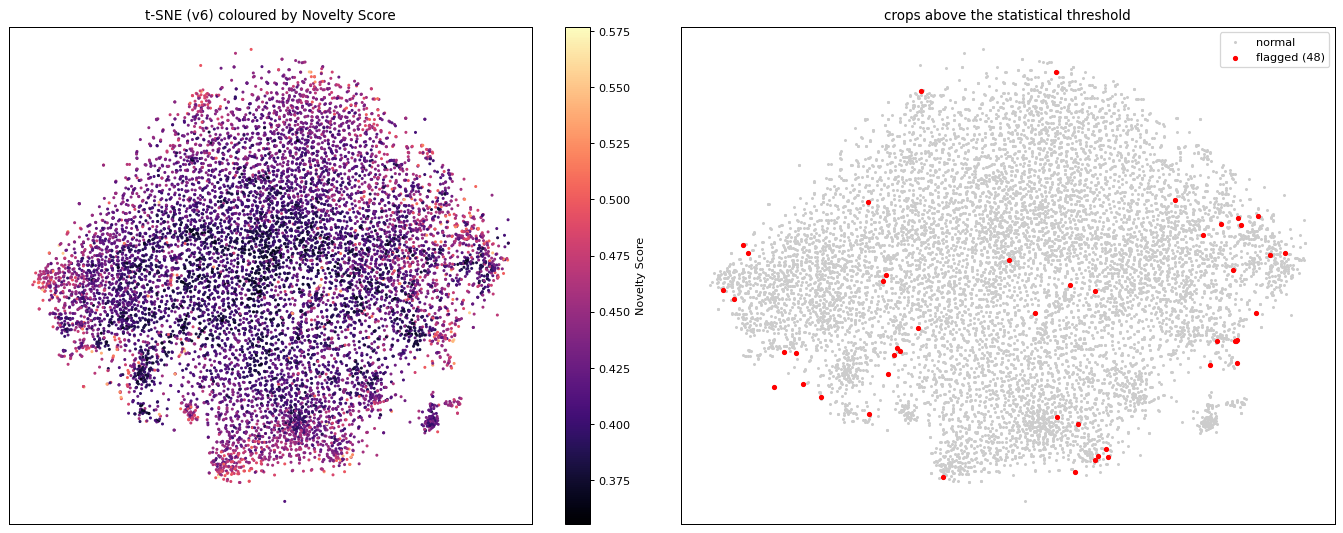

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sc = ax[0].scatter(E[:, 0], E[:, 1], c=nov, s=2, cmap="magma"); plt.colorbar(sc, ax=ax[0], label="Novelty Score")
ax[0].set_title(f"t-SNE ({FINAL}) coloured by Novelty Score")
ax[1].scatter(E[~flagged, 0], E[~flagged, 1], s=2, c="0.8", label="normal")
ax[1].scatter(E[flagged, 0], E[flagged, 1], s=10, c="r", label=f"flagged ({flagged.sum()})"); ax[1].legend()
ax[1].set_title("crops above the statistical threshold")
for a in ax: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); savefig("fig09_tsne_flagged.png"); plt.show()

### Contamination parameter

sklearn's `IsolationForest(contamination=...)` only changes the offset used by `predict()` to produce
±1 labels. It has **no effect on `score_samples()`**, which is all we use. We set
`contamination="auto"` (sklearn's default, offset −0.5), and we never call `predict()`. The final
anomaly count is determined solely by the statistical threshold on the continuous Novelty Score
above, **independently of any assumed contamination fraction**.

## 2.3 Image Location Analysis

Each scored crop is joined to `source_image_metadata.csv` through its `source_image_id` (from
`crop_metadata_index.csv`), many-to-one and validated. We then ask whether flags cluster in
particular observations, latitudes, illumination conditions, seasons or resolutions.

**Metadata resolution.** The provided coordinates are quantised. Latitude is on a 5° grid from −45°
to 60°, plus the two poles (±90°), and longitude takes only two values, 0° or 180°E (29 and 143
sources). A longitude-latitude map would collapse to two vertical lines, so we analyse
**latitude bands × the two longitudes** instead of point locations. We test
per-source enrichment with a one-sided binomial test against the global flag rate
(Bonferroni-corrected), and test trends with rank statistics (Spearman, Kruskal-Wallis), which
make no Gaussian assumption.

In [26]:
scored = crop_index.assign(novelty=nov, flagged=flagged, recon_mse=R[FINAL]["mse"], nodata=nodata) \
                   .merge(source_meta, on="source_image_id", how="left", validate="many_to_one")
assert scored.latitude.notna().all()
scored.to_csv(os.path.join(OUT, "novelty_scores_with_metadata.csv"), index=False)
print(scored.sort_values("novelty", ascending=False).head(15).to_string(index=False))

        filename source_image_id  novelty  flagged  recon_mse   nodata  latitude  longitude  sun_angle   season  resolution
sample_06476.jpg         SRC_158 0.576866     True   0.029539 0.006889      -5.0      180.0  35.954137 N-winter        0.25
sample_06963.jpg         SRC_166 0.566533     True   0.005104 0.000893      90.0        0.0  60.094207 N-spring        0.50
sample_07971.jpg         SRC_078 0.564267     True   0.015691 0.000000      15.0      180.0  40.437008 N-spring        0.25
sample_03383.jpg         SRC_067 0.558229     True   0.003277 0.035922     -15.0      180.0  64.724247 N-spring        0.50
sample_07701.jpg         SRC_136 0.557298     True   0.016968 0.000000     -35.0      180.0  76.922409 N-spring        0.50
sample_09828.jpg         SRC_156 0.556260     True   0.020977 0.000000      10.0      180.0  48.737382 N-summer        0.25
sample_06917.jpg         SRC_122 0.555504     True   0.002855 0.005900      -5.0      180.0  57.310506 N-summer        0.25
sample_0

In [27]:
per_src = scored.groupby("source_image_id").agg(n=("flagged", "size"), n_flag=("flagged", "sum"), mean_nov=("novelty", "mean"),
                                                 latitude=("latitude", "first"), longitude=("longitude", "first"),
                                                 sun_angle=("sun_angle", "first"), season=("season", "first"), resolution=("resolution", "first"))
per_src["rate"] = per_src.n_flag / per_src.n
base = scored.flagged.mean()
from scipy.stats import fisher_exact, binomtest
per_src["p_enrich"] = [binomtest(int(k), int(n), base, alternative="greater").pvalue for k, n in zip(per_src.n_flag, per_src.n)]
m_ = len(per_src); per_src["p_bonf"] = (per_src.p_enrich * m_).clip(upper=1)
print(f"base flag rate {base:.2%}; sources with >=1 flagged crop: {(per_src.n_flag > 0).sum()} / {m_}")
print(per_src.sort_values("n_flag", ascending=False).head(12).round(4).to_string())

base flag rate 0.46%; sources with >=1 flagged crop: 30 / 172
                   n  n_flag  mean_nov  latitude  longitude  sun_angle    season  resolution    rate  p_enrich  p_bonf
source_image_id                                                                                                       
SRC_039           16       9    0.5176      90.0        0.0    70.6328  N-summer        0.50  0.5625    0.0000   0.000
SRC_166           16       3    0.4933      90.0        0.0    60.0942  N-spring        0.50  0.1875    0.0001   0.009
SRC_032           14       2    0.4646      -5.0      180.0    52.4902  N-spring        0.25  0.1429    0.0019   0.320
SRC_022           74       2    0.4356      20.0      180.0    41.5136  N-spring        0.25  0.0270    0.0461   1.000
SRC_094           63       2    0.4170      20.0      180.0    66.9345  N-autumn        0.25  0.0317    0.0344   1.000
SRC_078           28       2    0.4031      15.0      180.0    40.4370  N-spring        0.25  0.0714    0

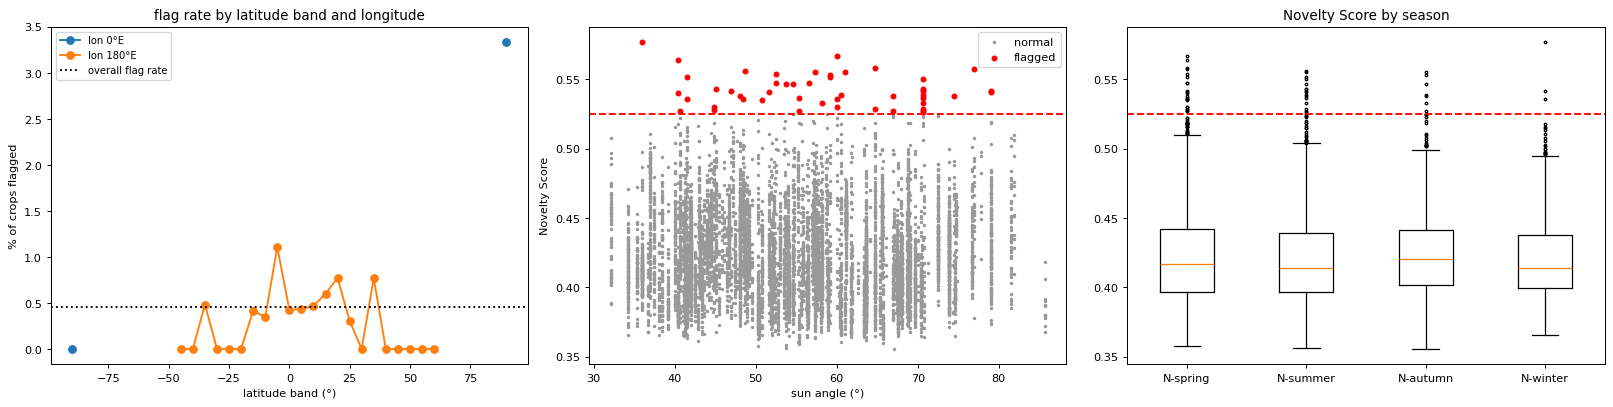

rho_sun          [-0.03076025640582555, 0.0016858741106929006]
rho_abslat       [0.057625328555702994, 3.9314429859255925e-09]
p_season         6.10343861546519e-05
p_resolution     1.2696233884062031e-06
p_chi2_season    0.5265268353586479
n_src_flagged    30.0
n_src_enriched   2.0


In [28]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
# the provided metadata is quantised: latitude on a 5° grid (plus the poles), longitude only 0° or 180°E
lat_rate = scored.groupby(["latitude", "longitude"]).flagged.mean().unstack()
for lon, c in zip(lat_rate.columns, ["tab:blue", "tab:orange"]):
    ax[0].plot(lat_rate.index, lat_rate[lon] * 100, "o-", c=c, label=f"lon {lon:.0f}°E")
ax[0].axhline(scored.flagged.mean() * 100, c="k", ls=":", label="overall flag rate")
ax[0].set_xlabel("latitude band (°)"); ax[0].set_ylabel("% of crops flagged"); ax[0].legend(fontsize=8)
ax[0].set_title("flag rate by latitude band and longitude")
for fl, c in [(False, "0.6"), (True, "r")]:
    d = scored[scored.flagged == fl]; ax[1].scatter(d.sun_angle, d.novelty, s=3 if not fl else 14, c=c, label="flagged" if fl else "normal")
ax[1].axhline(THRESHOLD, c="r", ls="--"); ax[1].set_xlabel("sun angle (°)"); ax[1].set_ylabel("Novelty Score"); ax[1].legend()
order_s = ["N-spring", "N-summer", "N-autumn", "N-winter"]
ax[2].boxplot([scored.novelty[scored.season == s] for s in order_s], tick_labels=order_s, showfliers=True, flierprops=dict(ms=2))
ax[2].axhline(THRESHOLD, c="r", ls="--"); ax[2].set_title("Novelty Score by season")
plt.tight_layout(); savefig("fig10_location.png"); plt.show()
from scipy.stats import spearmanr, kruskal, chi2_contingency
LOC = dict(
    rho_sun=spearmanr(scored.sun_angle, scored.novelty), rho_abslat=spearmanr(scored.latitude.abs(), scored.novelty),
    p_season=kruskal(*[scored.novelty[scored.season == s] for s in order_s]).pvalue,
    p_resolution=kruskal(*[g.novelty for _, g in scored.groupby("resolution")]).pvalue,
    p_chi2_season=chi2_contingency(pd.crosstab(scored.season, scored.flagged))[1],
    n_src_flagged=int((per_src.n_flag > 0).sum()), n_src_enriched=int((per_src.p_bonf < .05).sum()))
LOC = {k: ([float(v[0]), float(v[1])] if isinstance(v, tuple) or hasattr(v, "pvalue") else float(v)) for k, v in LOC.items()}
for k, v in LOC.items(): print(f"{k:16s} {v}")

**Findings (final model v6).**

* The 48 flags come from 30 of the 172 source observations. **Two sources are significantly
  enriched** (one-sided binomial test against the 0.46 % base rate, Bonferroni-corrected p < 0.05),
  and both are in the **90° N metadata bin**: SRC_039 (9 of its 16 crops flagged) and SRC_166 (3 of 16).
  Together they hold 12 of the 48 flags.
* **Physical reading: most likely rare terrain, not tampering.** These crops show bright ice-rich
  surfaces, finely banded layered deposits and scarps (e.g. the "stripes" of 08731 are layering, not
  sensor banding). This terrain is a small minority of the training crops, so its latents are easy to
  isolate. A mission pipeline would *route* such flags to the polar team rather than discard them; the
  metadata is what identifies them as a terrain class. Latitude is binned (the grid jumps from 60° to a
  90° bin), so "90° N" is a bin, not the pole itself; the 90° S bin has no flags.
* **The injected content is not location-specific.** The four Earth-like crops in the top 6 (06476,
  07971, 07701, 09828) come from four different observations between 35° S and 15° N, as expected if
  foreign crops were inserted at random positions.
* **Latitude.** Outside the 90° N bin the flag rate fluctuates around the base rate (0-1.1 %).
  Correlation with |latitude| is negligible (ρ = 0.06).
* **Illumination.** ρ(sun angle, novelty) = −0.03: detectable only because n = 10,422 and negligible in
  size; flagged crops span 36-79° of the dataset's 32-86° range.
* **Season.** Score *distributions* differ slightly between seasons (Kruskal-Wallis p ≈ 6·10⁻⁵), but
  *flagging* is independent of season (χ² p = 0.53).
* **Resolution.** Scores differ by resolution (p ≈ 10⁻⁶), consistent with the t-SNE observation that
  pixel scale changes texture frequency. The lone 1 m/px observation (SRC_111) has 2 of 137 crops
  flagged, so scale shifts the bulk of the distribution but does not by itself produce flags.

## 2.4 Optional Metadata Fusion (+2)

We concatenate the standardised image latent with an encoded metadata vector: z-scored sun angle,
sin/cos of latitude and longitude (to respect circularity), log₂ resolution, and a one-hot season.
We re-score with the same Isolation Forest settings and the same modified-z rule, then compare the
flagged sets. The image-only pipeline remains the primary result.

In [29]:
Zs = (R[FINAL]["Z"] - R[FINAL]["Z"].mean(0)) / (R[FINAL]["Z"].std(0) + 1e-8)
meta_vec = np.column_stack([
    (scored.sun_angle - scored.sun_angle.mean()) / scored.sun_angle.std(),
    np.sin(np.radians(scored.latitude)), np.cos(np.radians(scored.latitude)),
    np.sin(np.radians(scored.longitude)), np.cos(np.radians(scored.longitude)),
    np.log2(scored.resolution / 0.25),
    pd.get_dummies(scored.season).values.astype(float)])
fused = np.hstack([Zs, meta_vec])
nov_fused = novelty_scores(fused)[0]
thr_fused = mad_threshold(nov_fused, 3.5)   # same statistical rule as the image-only pipeline
flag_fused = nov_fused > thr_fused
a, b = set(np.where(flagged)[0]), set(np.where(flag_fused)[0])
FUS = dict(n_image=len(a), n_fused=len(b), overlap=len(a & b), jaccard=len(a & b) / len(a | b),
           rank_corr=float(pd.Series(nov).corr(pd.Series(nov_fused), method="spearman")),
           added=crop_index.filename[sorted(b - a)].tolist(), dropped=crop_index.filename[sorted(a - b)].tolist())
for k, v in FUS.items(): print(f"{k:10s} {v if not isinstance(v, list) else v[:15]}")

n_image    48
n_fused    54
overlap    46
jaccard    0.8214285714285714
rank_corr  0.9932709413728616
added      ['sample_04017.jpg', 'sample_04902.jpg', 'sample_05584.jpg', 'sample_06820.jpg', 'sample_09067.jpg', 'sample_09543.jpg', 'sample_09777.jpg', 'sample_10319.jpg']
dropped    ['sample_00606.jpg', 'sample_06351.jpg']


Fusion changes little: 54 crops are flagged against 48 image-only, with 46 in common (Jaccard 0.82)
and a rank correlation of 0.993 between the two scorings; fusion adds 8 crops and drops 2. Two
reasons explain the small effect:

1. The Isolation Forest picks split features uniformly at random, and only 10 of the 330 fused
   dimensions are metadata, so metadata drives about 3 % of splits.
2. Every crop from one observation shares identical metadata. Metadata can therefore isolate an
   unusual *observation*, but never a single crop within it, whereas the injected anomalies are
   single crops.

Metadata is therefore most useful as we used it in 2.3, to *explain* flags after the fact (e.g. the
polar enrichment), rather than as an input to detection.

# Phase 3 - Reconstruction Interpretability

## 3.1 Pixel-Wise Error Heatmaps

The five highest-scoring crops **within the statistically thresholded set** are passed back through
the Phase 1 decoder; for the two-stage final model this is stage 1's decoder, i.e. the image-space
reconstruction. The per-pixel squared error (validity-weighted smoothing, σ = 2 px) is shown alone and
overlaid on the original. The validity map is eroded by 3 px so JPEG ringing at a filled no-data
boundary is not read as error, and each map uses a robust colour scale (99.5th percentile of valid
pixels). To make the physical reading less subjective, we also compute descriptors of each error map
and image (`heatmap_descriptors`), each reported as a percentile against 500 random un-flagged crops:

* error **concentration** (share of error in the top 5 % of pixels)
* **line score** (a single-row or single-column error spike, as a seam would produce)
* **seam step** (the largest mean-intensity jump across a straight line)
* spectral **periodicity** (stripes or banding)
* **saturation** (clipped pixels)

In [30]:
# ---- nssc_core.py :: heatmaps
def error_map(orig, recon, smooth_sigma=2.0, valid=None):
    """Per-pixel squared error, lightly Gaussian-smoothed so structure is readable.
    If a validity map is given, no-data pixels are zeroed (they carry no terrain information)."""
    e = (orig - recon) ** 2
    if valid is None:
        return ndimage.gaussian_filter(e, smooth_sigma) if smooth_sigma else e
    if not smooth_sigma:
        return e * valid
    # validity-weighted smoothing: no-data pixels neither contribute error nor leak it into valid ones
    num = ndimage.gaussian_filter(e * valid, smooth_sigma)
    den = ndimage.gaussian_filter(valid.astype(float), smooth_sigma)
    return np.where(valid > 0, num / np.maximum(den, 1e-6), 0.0)


def heatmap_descriptors(orig, err, valid=None):
    """Quantitative descriptors of an error map that support the physical hypotheses.

    concentration : share of total error in the top 5% of pixels (1.0 = all in a few pixels,
                    ~0.05 = perfectly diffuse)
    line_score    : strongest single-row or single-column mean error relative to the median
                    row/column (a straight seam gives a sharp spike)
    seam_step     : largest mean-intensity jump between the two halves on either side of any
                    horizontal/vertical line (spliced terrain with mismatched albedo)
    periodicity   : fraction of non-DC spectral power held by the 20 strongest frequencies
                    (stripes / banding from sensor read-out)
    saturation    : fraction of valid pixels at 0 or 1 (clipped / dead / hot pixels)
    """
    v = np.ones_like(orig, bool) if valid is None else valid.astype(bool)
    flat = np.sort(err[v].ravel())[::-1]
    conc = flat[: max(1, len(flat) // 20)].sum() / max(flat.sum(), 1e-12)
    rows = (err * v).sum(1) / np.maximum(v.sum(1), 1)          # row / column means over valid pixels only
    cols = (err * v).sum(0) / np.maximum(v.sum(0), 1)
    line = max(rows.max() / (np.median(rows) + 1e-12), cols.max() / (np.median(cols) + 1e-12))
    cr, cc = np.cumsum(orig.mean(1)), np.cumsum(orig.mean(0))
    n = orig.shape[0]
    steps = []
    for c in (cr, cc):
        for i in range(20, n - 20):
            steps.append(abs(c[i - 1] / i - (c[-1] - c[i - 1]) / (n - i)))
    spec = np.abs(np.fft.fftshift(np.fft.fft2(orig - orig.mean()))) ** 2
    spec[n // 2, n // 2] = 0
    top = np.sort(spec.ravel())[::-1]
    o = orig[v]
    return dict(concentration=conc, line_score=line, seam_step=max(steps),
                periodicity=top[:20].sum() / top.sum(),
                saturation=float(((o <= 1 / 255) | (o >= 254 / 255)).mean()),
                mean=o.mean(), std=o.std())

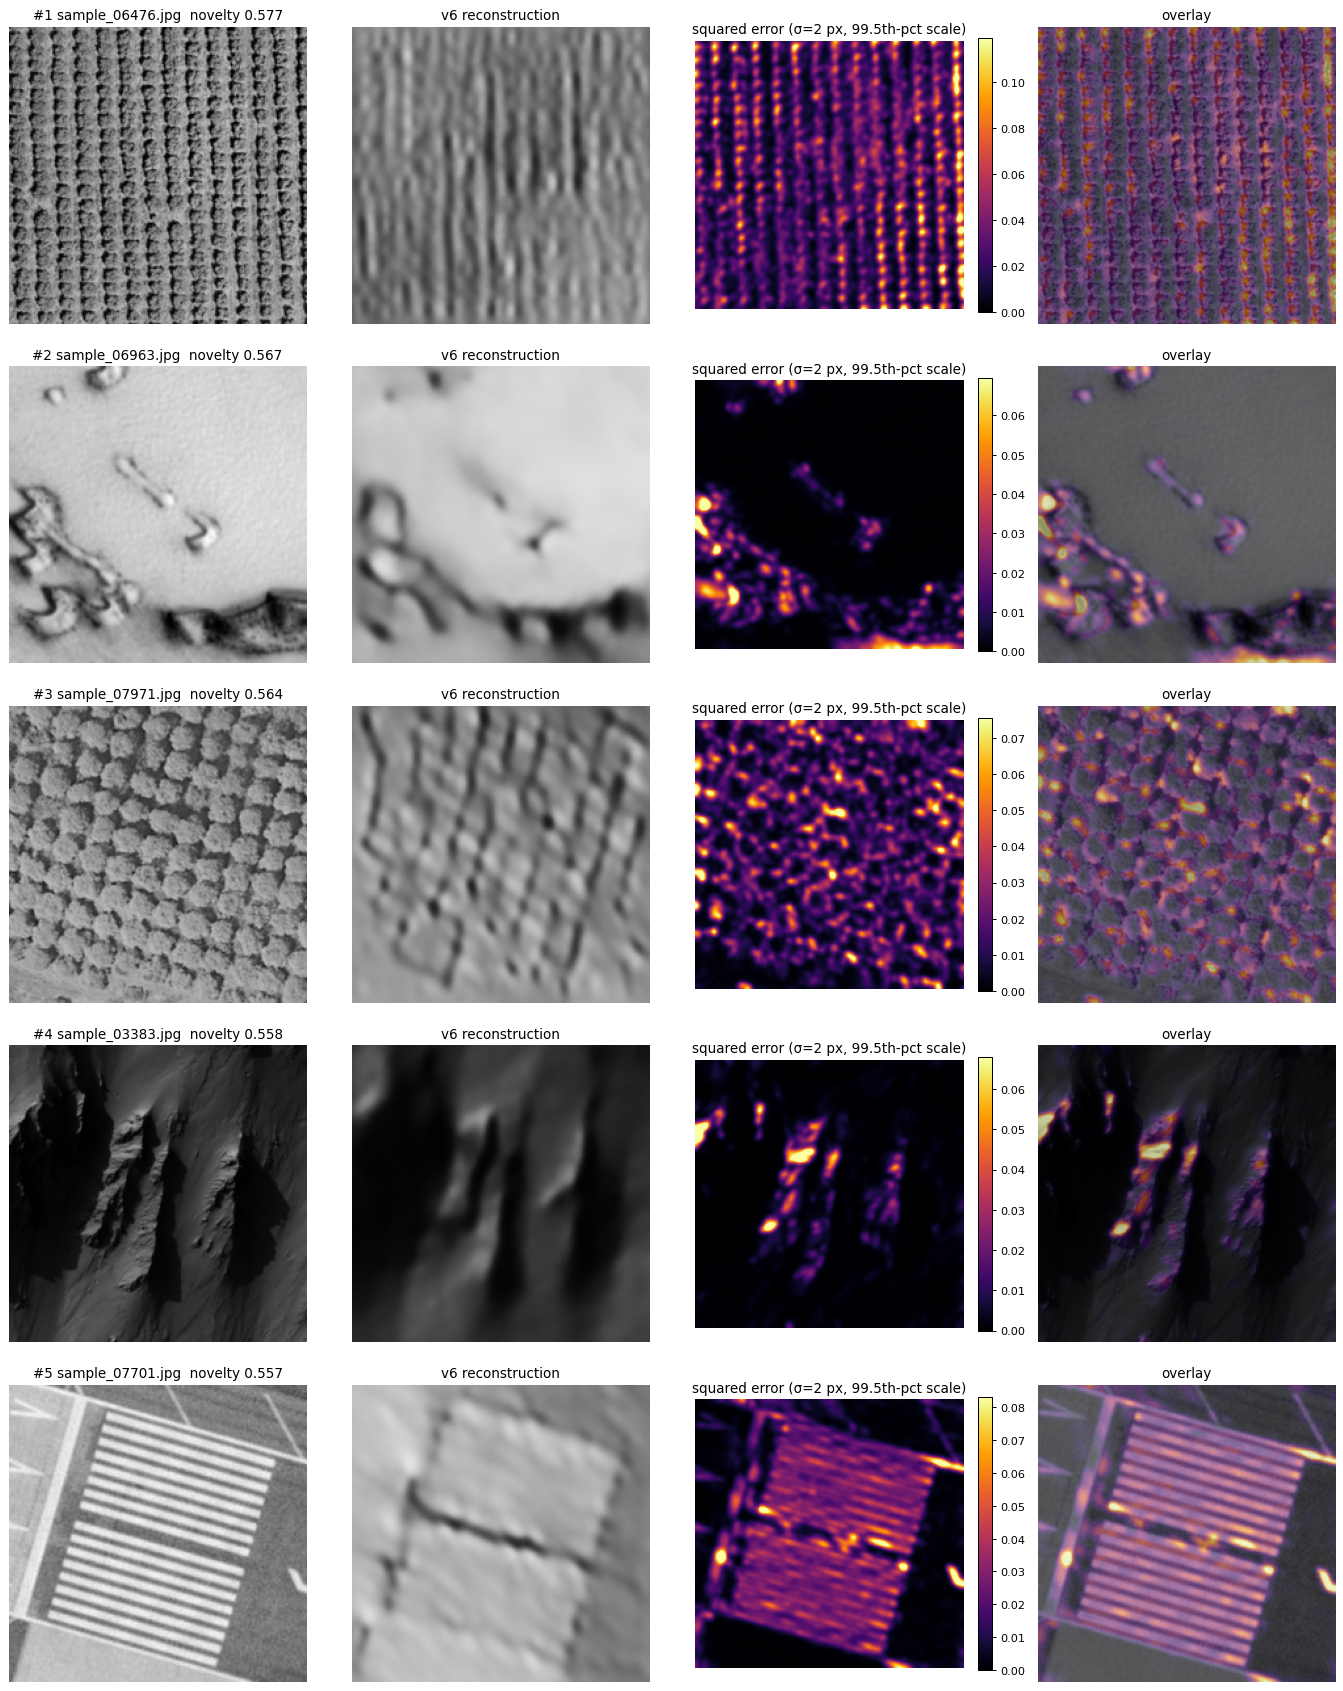

 rank         filename  source  novelty  recon_mse  concentration  line_score  seam_step  periodicity  saturation   mean    std
    1 sample_06476.jpg SRC_158   0.5769     0.0295         0.1563      2.7904     0.0475       0.3831      0.0044 0.4471 0.1752
    2 sample_06963.jpg SRC_166   0.5665     0.0051         0.4469      5.2276     0.2630       0.6247      0.0005 0.7017 0.1810
    3 sample_07971.jpg SRC_078   0.5643     0.0157         0.1843      1.5627     0.0821       0.3999      0.0000 0.5037 0.1370
    4 sample_03383.jpg SRC_067   0.5582     0.0033         0.5301      4.7143     0.0703       0.4949      0.0195 0.1569 0.1159
    5 sample_07701.jpg SRC_136   0.5573     0.0170         0.1647      1.4508     0.1976       0.5066      0.0000 0.6567 0.1691


In [31]:
flag_idx = np.where(flagged)[0]
top5 = flag_idx[np.argsort(-nov[flag_idx])][:5]      # top-5 *within* the thresholded set
Xin, Min = INPUT[FINAL]                                # v3 decoder input: no-data filled
orig, rec = reconstruct(R[FINAL]["model"], Xin, top5)
valid = np.ones_like(orig) if Min is None else 1.0 - Min[top5]
# erode the validity map by 3 px so JPEG ringing at a filled-wedge boundary is not read as error
valid = np.stack([ndimage.binary_erosion(v > 0, iterations=3, border_value=1) for v in valid]).astype(float)
fig, ax = plt.subplots(len(top5), 4, figsize=(15, 3.8 * len(top5)), squeeze=False)
desc = []
for r_, i in enumerate(top5):
    e = error_map(orig[r_], rec[r_], valid=valid[r_])  # no-data pixels carry no error by construction
    vmax = np.percentile(e[valid[r_] > 0], 99.5)       # robust colour scale: a few hot pixels cannot wash out the map
    desc.append(dict(rank=r_ + 1, filename=crop_index.filename[i], source=crop_index.source_image_id[i],
                     novelty=nov[i], recon_mse=R[FINAL]["mse"][i], **heatmap_descriptors(orig[r_], e, valid[r_])))
    ax[r_, 0].imshow(X[i], cmap="gray", vmin=0, vmax=255); ax[r_, 0].set_title(f"#{r_+1} {crop_index.filename[i]}  novelty {nov[i]:.3f}")
    ax[r_, 1].imshow(rec[r_], cmap="gray", vmin=0, vmax=1); ax[r_, 1].set_title(f"{FINAL} reconstruction")
    im = ax[r_, 2].imshow(e, cmap="inferno", vmin=0, vmax=vmax); plt.colorbar(im, ax=ax[r_, 2], fraction=.046)
    ax[r_, 2].set_title("squared error (σ=2 px, 99.5th-pct scale)")
    ax[r_, 3].imshow(X[i], cmap="gray", vmin=0, vmax=255); ax[r_, 3].imshow(e, cmap="inferno", alpha=.55, vmin=0, vmax=vmax)
    ax[r_, 3].set_title("overlay")
for a in ax.ravel(): a.axis("off")
plt.tight_layout(); savefig("fig11_heatmaps_top5.png"); plt.show()
desc = pd.DataFrame(desc); print(desc.round(4).to_string(index=False))

In [32]:
# reference: the same descriptors on 500 random un-flagged crops, to say what "unusual" means
rng = np.random.default_rng(0); ref_idx = rng.choice(np.where(~flagged)[0], 500, replace=False)
Xin, Min = INPUT[FINAL]
o_, r_ = reconstruct(R[FINAL]["model"], Xin, ref_idx)
v_ = np.ones_like(o_) if Min is None else 1.0 - Min[ref_idx]
v_ = np.stack([ndimage.binary_erosion(v > 0, iterations=3, border_value=1) for v in v_]).astype(float)
ref = pd.DataFrame([heatmap_descriptors(o_[k], error_map(o_[k], r_[k], valid=v_[k]), v_[k]) for k in range(len(ref_idx))])
pct = desc[ref.columns].apply(lambda col: [(ref[col.name] < v).mean() * 100 for v in col])
pct.insert(0, "filename", desc.filename)
print("percentile of each top-5 descriptor relative to 500 normal crops:"); print(pct.round(0).to_string(index=False))

percentile of each top-5 descriptor relative to 500 normal crops:
        filename  concentration  line_score  seam_step  periodicity  saturation  mean   std
sample_06476.jpg            2.0        39.0       58.0         57.0        99.0  37.0 100.0
sample_06963.jpg           88.0        77.0      100.0         83.0        89.0  94.0 100.0
sample_07971.jpg            5.0         2.0       86.0         59.0         0.0  56.0 100.0
sample_03383.jpg           96.0        72.0       81.0         70.0       100.0   1.0  99.0
sample_07701.jpg            3.0         0.0      100.0         71.0         0.0  91.0 100.0


### 3.1b Supplementary heatmaps: visually noticed crops (flagged and missed)

Pentagon (terrestrial)   rank     6 | recon-MSE percentile 100.0 | concentration 0.18 | line score 1.7
periodic grid            rank     1 | recon-MSE percentile 100.0 | concentration 0.16 | line score 2.8
bright + thin line       rank    16 | recon-MSE percentile  98.6 | concentration 0.26 | line score 2.3
black bar                rank   344 | recon-MSE percentile  99.4 | concentration 0.27 | line score 4.6
two streaks              rank  2517 | recon-MSE percentile  98.6 | concentration 0.34 | line score 5.4
dead-pixel blocks        rank   479 | recon-MSE percentile  52.5 | concentration 0.19 | line score 2.1


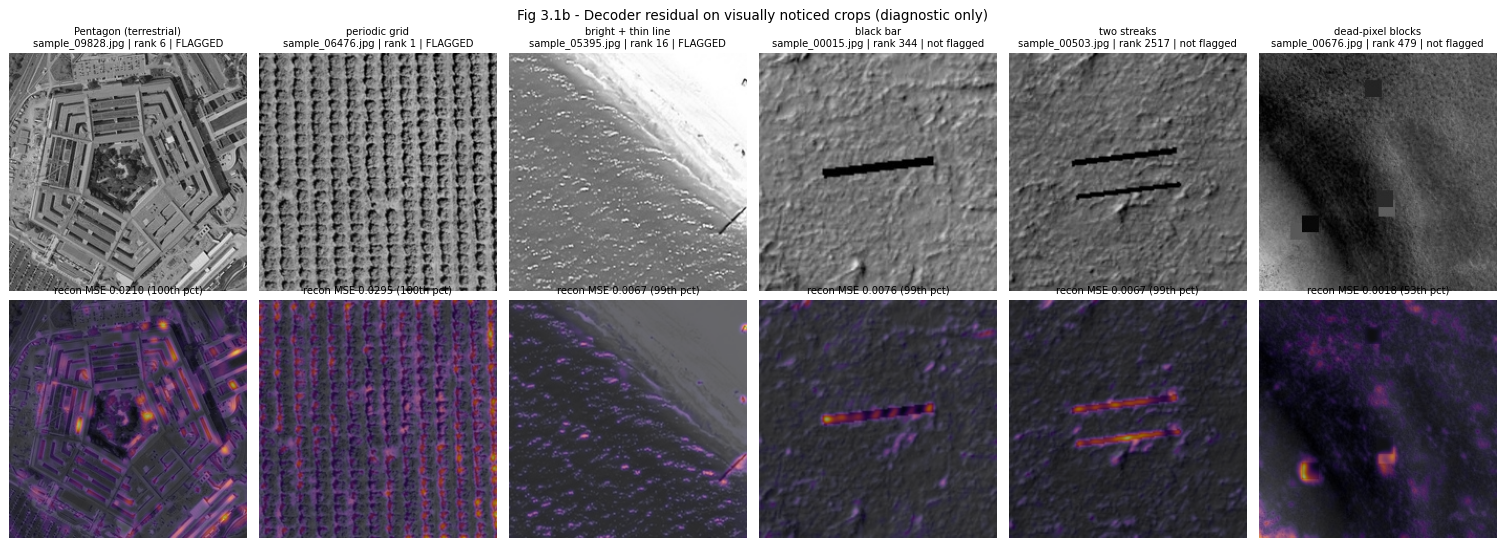

In [33]:
supp = {9828: "Pentagon (terrestrial)", 6476: "periodic grid", 5395: "bright + thin line",
        15: "black bar", 503: "two streaks", 676: "dead-pixel blocks"}
idx_s = np.array([k - 1 for k in supp])
Xin, Min = INPUT[FINAL]
o_s, r_s = reconstruct(R[FINAL]["model"], Xin, idx_s)
v_s = np.ones_like(o_s) if Min is None else 1.0 - Min[idx_s]
v_s = np.stack([ndimage.binary_erosion(v > 0, iterations=3, border_value=1) for v in v_s]).astype(float)
rank_all = (-nov).argsort().argsort() + 1
fig, ax = plt.subplots(2, len(idx_s), figsize=(2.8 * len(idx_s), 6.2))
for j, (i, lab) in enumerate(zip(idx_s, supp.values())):
    e = error_map(o_s[j], r_s[j], valid=v_s[j])
    mse_pct = (R[FINAL]["mse"] < R[FINAL]["mse"][i]).mean() * 100
    d_ = heatmap_descriptors(o_s[j], e, v_s[j])
    print(f"{lab:24s} rank {rank_all[i]:5d} | recon-MSE percentile {mse_pct:5.1f} | concentration {d_['concentration']:.2f} | line score {d_['line_score']:.1f}")
    ax[0, j].imshow(X[i], cmap="gray", vmin=0, vmax=255)
    ax[0, j].set_title(f"{lab}\n{crop_index.filename[i]} | rank {rank_all[i]} | {'FLAGGED' if flagged[i] else 'not flagged'}", fontsize=8)
    ax[1, j].imshow(X[i], cmap="gray", vmin=0, vmax=255); ax[1, j].imshow(e, cmap="inferno", alpha=.6)
    ax[1, j].set_title(f"recon MSE {R[FINAL]['mse'][i]:.4f} ({mse_pct:.0f}th pct)", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Fig 3.1b - Decoder residual on visually noticed crops (diagnostic only)"); plt.tight_layout()
savefig("fig11b_supplementary_heatmaps.png"); plt.show()

## 3.2 Geological Report

These are **hypotheses**, argued from the heatmap pattern, the descriptors (with percentiles against
500 normal crops) and the metadata. They are not definitive classifications. A quantitative pattern
runs through the top 5: the three crops whose error is **diffuse** (concentration at the 2nd-5th
percentile) are exactly the three with **very high** reconstruction error (0.016-0.030, against
0.003-0.005 for the other two), and all three look man-made.

**#1 sample_06476 (SRC_158, 5° S): straight rows of rounded, shadow-casting objects. Hypothesis:
terrestrial content (an orchard or plantation seen from above).** A near-perfect lattice of rounded
blobs in straight rows is a geometry no Martian process produces at this scale. The decoder, which has
only a Martian vocabulary, returns a smeared stripe pattern; the error covers **every blob in the
frame** (concentration 0.16, 2nd percentile) and the reconstruction error is at the 100th percentile of
the dataset (0.0295). This is the textbook **non-Martian domain-shift** signature.

**#2 sample_06963 (SRC_166, 90° N bin): bright plain with dark, angular knobs. Hypothesis: genuine
polar terrain.** A bright, smooth surface carries scattered dark knobs and a dark scarp margin at the
bottom. The error is **concentrated on the dark relief** (concentration at the 88th percentile) and
the reconstruction error is low (0.0051), so the decoder understands the scene and only misses the
sharp dark features. SRC_166 is one of the two significantly enriched polar observations (2.3).

**#3 sample_07971 (SRC_078, 15° N): densely packed rounded crowns. Hypothesis: terrestrial content
(tree canopy or orchard).** Tightly packed, rounded, textured crowns with dark gaps between them form a
loose grid. As for #1, the error is **spread across the whole frame** (concentration 0.18, 5th
percentile) and the reconstruction error is very high (0.0157), with the decoder falling back to a
blurred cratered texture. Diffuse whole-frame failure again points to a **domain shift** rather than
an unusual Martian feature.

**#4 sample_03383 (SRC_067, 15° S): dark, low-sun rugged relief. Hypothesis: genuine massifs or ridges
under oblique illumination.** The frame is darker than 99 % of reference crops, its contrast is at the
99th percentile, and the error is concentrated on the **thin sunlit crests** (concentration at the
96th percentile), not in the shadows. Long shadows from steep spurs make a high-contrast,
high-frequency pattern whose exact crest geometry the code cannot store: rare, but Martian.

**#5 sample_07701 (SRC_136, 35° S): evenly spaced bright bars inside rectangles, beside straight
lines. Hypothesis: terrestrial content (runway or apron markings) or a synthetic insertion.** Two
rectangular blocks of parallel bright bars bounded by straight edges sit next to a straight bright band
and a thin line network: rectilinear, periodic, painted-looking geometry. The error follows **every bar
and edge** (concentration 0.16, 3rd percentile; seam step at the 100th percentile because of the sharp
straight boundaries) and the reconstruction error is high (0.0170). The regularity and the diffuse
failure match the domain-shift signature of #1 and #3. v3 flagged this crop but ranked it much lower;
v6's residual code lifted it into the top 5.

**Beyond the top 5 (Fig 3.1b, diagnostic).** The **Pentagon** aerial photograph ranks 6th, with
reconstruction error at the 100th percentile spread diffusely over the frame (concentration 0.18). The
**black bar** and **two streaks** are not flagged (ranks 344 and 2,517) but sit at the 99.4th and
98.6th percentiles of reconstruction error, with the error lying *along the straight dark defect* (line
scores 4.6 and 5.4, the highest in the table): the **synthetic sensor-artefact** signature, still
partly hidden from the latent. The dead-pixel blocks are invisible even to the residual (52nd
percentile).

| heatmap pattern | examples | physical hypothesis |
|---|---|---|
| intense error over the whole frame + very high reconstruction error | 06476, 07971, 07701, Pentagon 09828 | domain shift: non-Martian (man-made) content |
| error concentrated on sharp relief, low reconstruction error | 06963, 03383 | rare genuine terrain (polar knobs, low-sun ridges) |
| error along a straight dark line | bar 00015, streaks 00503 | synthetic sensor artefact (missed by the latent) |

# Phase 4 - Architecture Iteration & Design Journal

Every version was trained with identical data, schedule and seed. The table below is the
quantitative evidence referenced in each changelog entry, followed by the planted-fakes benchmark.
The full journal is also in `CHANGELOG.md`.

Note: `val_mse` / `val_ssim` of v1-v2 include no-data pixels, whereas v3 onwards are computed on valid
pixels only, so those columns are not strictly like-for-like. v6 reports its stage-1 (= v3) values.

In [34]:
rows = []
for v in VERSIONS:
    h, n_ = R[v]["hist"], R[v]["nov"]
    thr_v = mad_threshold(n_, 3.5)
    Zv = R[v]["Z"]; pv = np.linalg.svd(Zv - Zv.mean(0), compute_uv=False) ** 2; pv /= pv.sum()
    rows.append(dict(version=v, val_mse=h.val_mse.iloc[-1], val_ssim=h.val_ssim.iloc[-1],
                     nodata_mse_ratio=R[v]["mse"][nodata > .1].mean() / R[v]["mse"][nodata < .01].mean(),
                     pca90=int(np.searchsorted(np.cumsum(pv), .9) + 1),
                     corr_nov_nodata=pd.Series(n_).corr(pd.Series(nodata), method="spearman"),
                     n_flag_mad35=int((n_ > thr_v).sum()),
                     flagged_with_nodata=float((nodata[n_ > thr_v] > .01).mean())))
cmp = pd.DataFrame(rows); print(cmp.round(4).to_string(index=False))

version  val_mse  val_ssim  nodata_mse_ratio  pca90  corr_nov_nodata  n_flag_mad35  flagged_with_nodata
     v1   0.0019    0.7053            1.0011     44           0.6347          1596               0.9655
     v2   0.0023    0.7065            1.0157     36           0.6571          1985               0.9597
     v3   0.0021    0.7195            1.1564    190           0.1100            86               0.4767
     v4   0.0022    0.7159            1.1597    139           0.0659           510               0.3353
     v5   0.0100    0.5308            1.0173    187          -0.3746             0                  NaN
     v6   0.0021    0.7195            1.1564    238           0.0968            48               0.4583


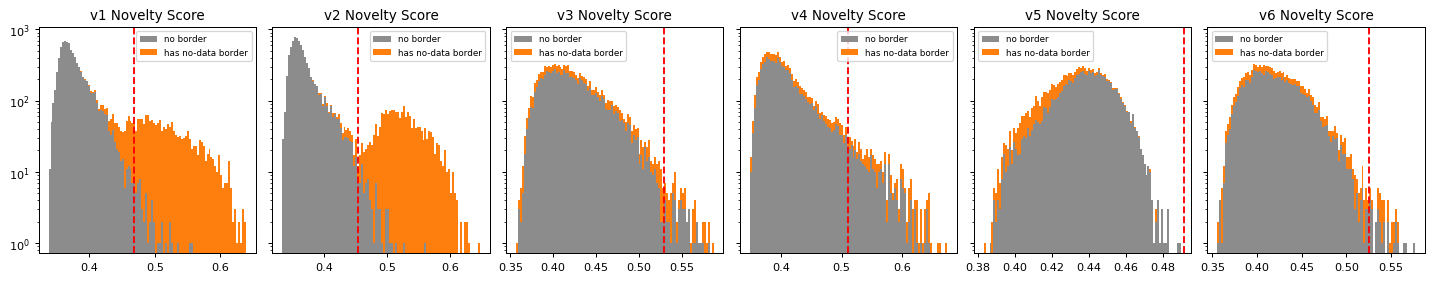

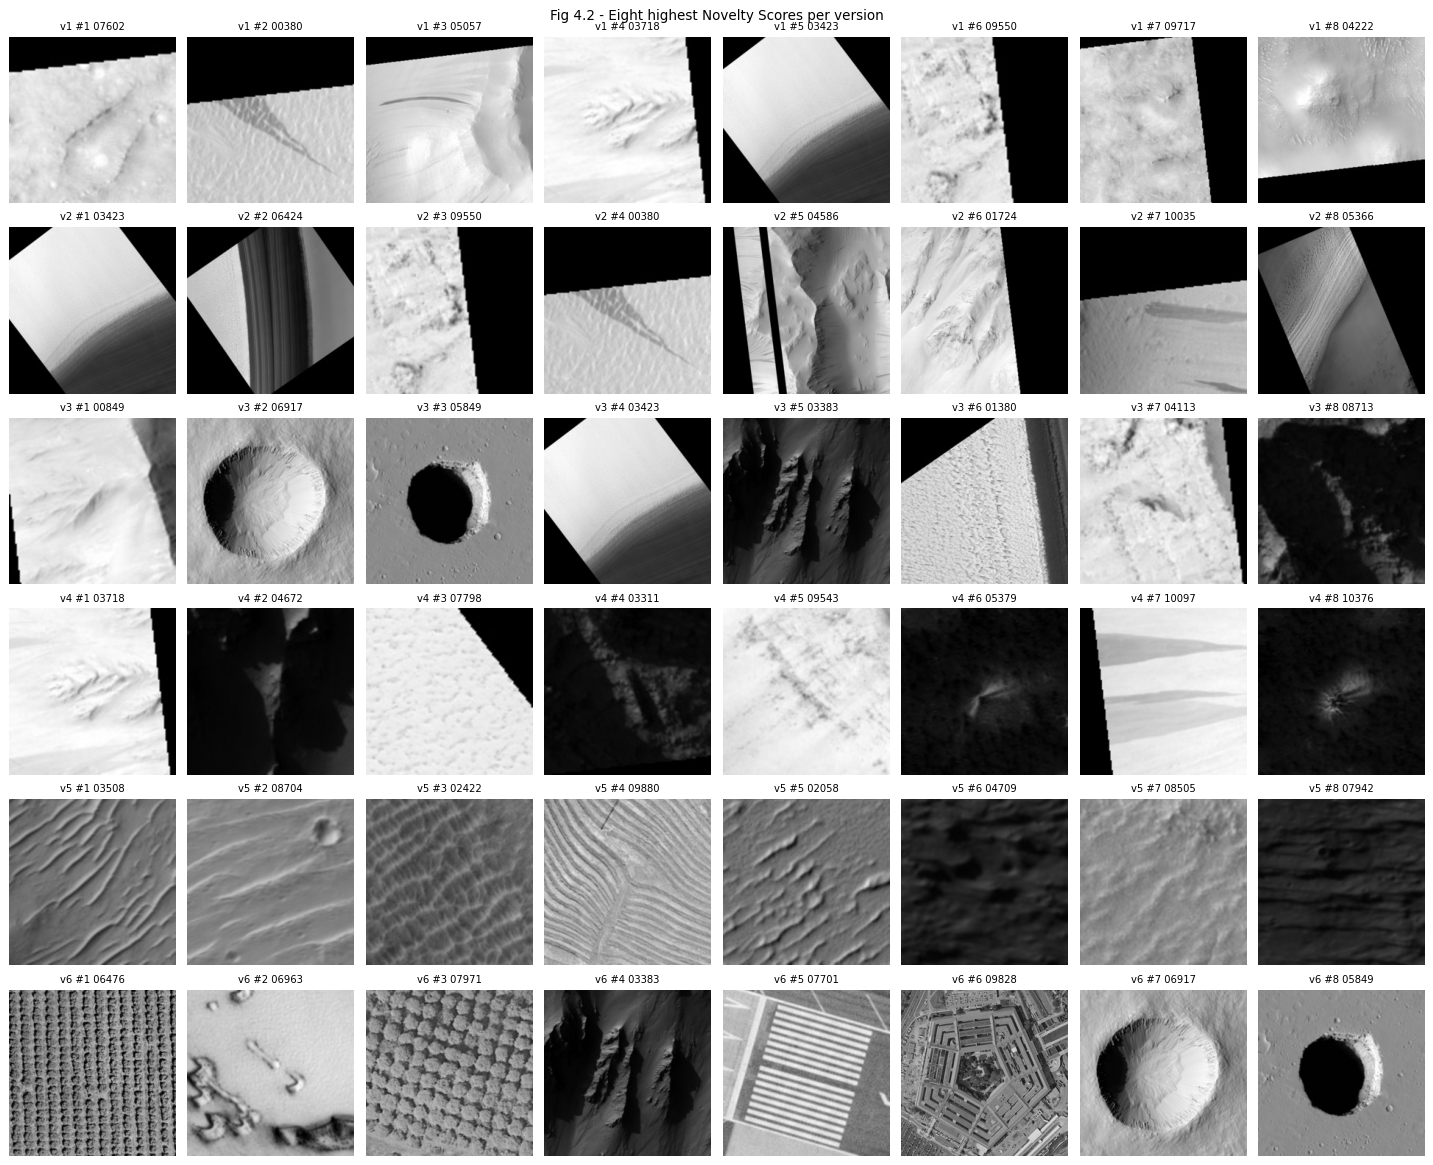

In [35]:
fig, ax = plt.subplots(1, len(VERSIONS), figsize=(16, 3.2), sharey=True)
for a, v in zip(ax, VERSIONS):
    n_ = R[v]["nov"]; b_ = nodata > .01
    a.hist([n_[~b_], n_[b_]], 100, stacked=True, color=["0.55", "tab:orange"], label=["no border", "has no-data border"], log=True)
    a.axvline(mad_threshold(n_, 3.5), c="r", ls="--"); a.set_title(f"{v} Novelty Score"); a.legend(fontsize=7)
plt.tight_layout(); savefig("fig12_versions_hist.png"); plt.show()
fig, ax = plt.subplots(len(VERSIONS), 8, figsize=(16, 2.2 * len(VERSIONS)))
for r_, v in enumerate(VERSIONS):
    for c_, i in enumerate(np.argsort(-R[v]["nov"])[:8]):
        ax[r_, c_].imshow(X[i], cmap="gray", vmin=0, vmax=255); ax[r_, c_].set_title(f"{v} #{c_+1} {crop_index.filename[i][7:12]}", fontsize=8)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Fig 4.2 - Eight highest Novelty Scores per version"); plt.tight_layout(); savefig("fig13_versions_top8.png"); plt.show()

In [36]:
# Spot checks: crops we noticed by eye (sanity pass / earlier versions). Used only to diagnose
# failure modes in the changelog - never to choose the threshold.
SPOT = {15: "black bar", 503: "two streaks", 676: "dead-pixel blocks", 9828: "Pentagon (terrestrial)",
        5508: "terrestrial buildings", 6476: "periodic grid", 7971: "periodic grid", 5395: "bright + thin line",
        11: "dark terrain (control)", 385: "dark terrain (control)"}
spot = pd.DataFrame({"note": list(SPOT.values())}, index=[f"sample_{k:05d}.jpg" for k in SPOT])
for v in VERSIONS:
    n_ = R[v]["nov"]; rank = (-n_).argsort().argsort() + 1; thr_v = mad_threshold(n_, 3.5)
    spot[f"{v} rank"] = [int(rank[k - 1]) for k in SPOT]
    spot[f"{v} flagged"] = [bool(n_[k - 1] > thr_v) for k in SPOT]
print(spot.to_string())

                                    note  v1 rank  v1 flagged  v2 rank  v2 flagged  v3 rank  v3 flagged  v4 rank  v4 flagged  v5 rank  v5 flagged  v6 rank  v6 flagged
sample_00015.jpg               black bar     4499       False     3859       False     1120       False     2833       False     5518       False      344       False
sample_00503.jpg             two streaks     7419       False     5171       False     2211       False     3158       False     4051       False     2517       False
sample_00676.jpg       dead-pixel blocks     1571        True     1915        True      304       False      872       False     8430       False      479       False
sample_09828.jpg  Pentagon (terrestrial)     2875       False     2275       False       47        True      488        True     3055       False        6        True
sample_05508.jpg   terrestrial buildings     2681       False     2494       False      354       False      512       False     4123       False      156       Fals

### Planted-fakes benchmark (model-selection evidence)

Without ground truth a model cannot be scored directly. `benchmark.py` therefore plants 2,400 synthetic
anomalies into clean crops: 300 each of eight types, namely straight-seam and patch splices; bars,
blocks, gain stripes and line dropouts; and periodic and rectilinear man-made textures. The fakes pass
through exactly the same pre-processing as real crops and are scored by each version's Isolation Forest
fitted on the **real** crops only. AUROC measures how well a version ranks fakes above real crops
(0.5 = chance); recall is the share caught by that version's own statistical threshold. The threshold
rule is **never** tuned on this benchmark. It is used only to compare versions, and it is a proxy,
because our generators may differ from the organisers' injections.

                  auroc_splice  auroc_glitch  auroc_domain  auroc_mean  recall_mean  n_flag_real  auroc_recon_mean
model                                                                                                             
v1                       0.578         0.509         0.392       0.497        0.046         1596             0.835
v2                       0.509         0.559         0.387       0.504        0.032         1985             0.840
v3                       0.611         0.724         0.882       0.735        0.095           86             0.835
v4                       0.564         0.659         0.669       0.638        0.063          510             0.832
raw pixels 32x32         0.518         0.457         0.382       0.453        0.010          485               NaN
v5                       0.446         0.333         0.467       0.395        0.000            0             0.605
v6                       0.650         0.769         0.912       0.775        0.

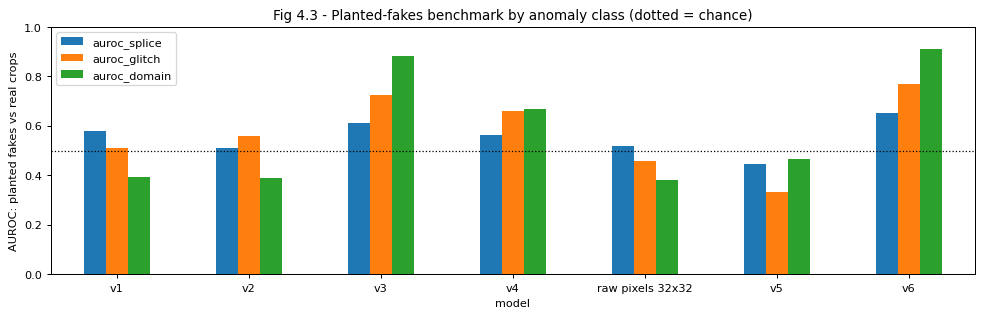

In [37]:
bench = pd.concat([pd.read_csv(p, index_col=0) for p in sorted(glob.glob(os.path.join(OUT, "bench_*_summary.csv")))])
bench = bench[~bench.index.duplicated(keep="last")]
cols = ["auroc_splice", "auroc_glitch", "auroc_domain", "auroc_mean", "recall_mean", "n_flag_real", "auroc_recon_mean"]
print(bench[cols].round(3).to_string())
ax = bench[["auroc_splice", "auroc_glitch", "auroc_domain"]].plot.bar(figsize=(11, 3.6), rot=0)
ax.axhline(0.5, c="k", ls=":", lw=1); ax.set_ylim(0, 1); ax.set_ylabel("AUROC: planted fakes vs real crops"); ax.set_xlabel("model")
plt.title("Fig 4.3 - Planted-fakes benchmark by anomaly class (dotted = chance)"); plt.tight_layout(); savefig("fig14_benchmark.png"); plt.show()

Every version uses identical data (10,422 crops), a random 90/10 split held out for loss curves,
AdamW + one-cycle LR (max 1e-3), batch 64, 30 epochs, horizontal/vertical flip augmentation,
bf16 autocast, seed 42, and the same Isolation Forest (500 trees, ψ = 256, 5 seeds averaged).
Each version changes **one** thing, so its effect can be attributed.

---

## v1 - Baseline: convolutional AE, pure MSE

**Setup.** 5× stride-2 conv encoder (32-64-128-256-256) → Linear → 256-d latent; mirrored
transposed-conv decoder; loss = MSE.

**Result.** Held-out MSE 0.00189, SSIM 0.705 after 30 epochs (SSIM plateaued from about epoch 20; MSE kept falling slowly).

### Symptom 1 - Blurry reconstructions, fine texture erased
Dune ripple trains, small-crater fields and rough ground are reconstructed as smooth grey gradients
(outputs/v1/recon_grid.png, random crops 07869 and 01503). The error maps of *normal* crops are
dominated by texture, not by anything anomalous.

### Symptom 2 - The novelty engine ranks map-projection borders, not anomalies
* All of the top-25 Novelty Scores are crops with a black no-data wedge (the edge of the
  map-projected HiRISE strip). Their error maps are just a bright line tracing the wedge edge.
* Spearman ρ(novelty, reconstruction MSE) = −0.095: what the forest isolates is unrelated to what
  the decoder fails to explain.
* The score histogram has a long secondary shoulder (0.45-0.63) holding about 18 % of the crops, which
  is roughly the share of crops with a border. Even the robust modified-z rule (median + 3.5 MAD) therefore
  flags 1,596 crops (15.3 %), and the elbow and GMM rules flag even more. No defensible threshold can
  exist while a nuisance factor forms its own mode.
* One latent coordinate has variance 2,800 against a median of 33, so the code spends its largest
  axis on border geometry.

### Diagnosis
1. **Blur:** MSE is minimised by the conditional mean. When the exact phase of a ripple or
   the rim of a small crater is uncertain, averaging the possibilities gives the lowest expected
   squared error. The decoder learns to hedge, which erases exactly the high-frequency geology we
   need in order to notice unfamiliar texture.
2. **Borders:** a no-data wedge is a 0-valued region with a razor-sharp straight edge at an
   arbitrary angle and position. It is the highest-contrast structure in the dataset. Under MSE it
   dominates the loss, so the encoder dedicates capacity to encoding wedge geometry. In the latent
   space, crops with rare wedge angles are then the easiest points to isolate.

### Fix
Addressed one at a time: v2 changes only the loss (symptom 1); v3 addresses the no-data
nuisance (symptom 2).

---

## v2 - Structural loss: 0.84·(1 − SSIM) + 0.16·L1 + 0.1·Gradient-L1

**Change (loss only; architecture, data and schedule identical to v1).**

* **SSIM** (11×11 Gaussian window) penalises lost local contrast and structure even when mean
  brightness is right, which directly targets blur. The 0.84 / 0.16 split follows Zhao et al. (2017,
  *Loss Functions for Image Restoration with Neural Networks*).
* **L1** replaces MSE as the intensity anchor. SSIM ignores uniform offsets, and L1 is less dominated
  by a few huge errors than MSE.
* **Gradient-L1** on finite differences penalises smeared ridgelines and crater rims.

**Outcome.**

| | v1 | v2 |
|---|---|---|
| held-out SSIM | 0.7053 | 0.7065 |
| held-out MSE | 0.00189 | 0.00228 |
| PCA components for 90 % latent variance | 44 | 36 |
| Spearman ρ(novelty, no-data fraction) | 0.63 | **0.66** |
| crops flagged by modified-z > 3.5 | 1,596 | 1,985 |

### Symptom 1 (blur) - essentially unchanged
Crater rims are slightly crisper, but dune ripples (crop 01503) and small-crater fields are still
reconstructed as smooth gradients, and held-out SSIM moved by only +0.001.

**Diagnosis.** The loss was not the binding constraint. The code has only 256 floats for 51,529
pixels (≈200× compression), squeezed through a single linear layer from an 8×8×256 map. The exact
phase of a ripple field is high-entropy information that such a code cannot store. Whatever the
loss, the decoder can only output the "texture class" with its details averaged out. **Lesson:**
the loss decides *how* the unavoidable error is distributed; it cannot create information the
bottleneck discarded. For anomaly detection this matters less than it first seemed. The latent
only has to encode *what kind of* terrain a crop is, which it can do without reproducing every
ripple.

### Symptom 2 (no-data borders) - got worse
The novelty histogram (outputs/v2/scores.png) is now clearly **bimodal**. The second mode
(0.47-0.60) is almost entirely crops with a black no-data wedge. ρ(novelty, no-data fraction), already
0.63 under v1, rose to 0.66. The number flagged grew from 1,596 to 1,985, and every crop in the
top 25 has a wedge.

**Diagnosis.** Both new loss terms are *edge-sensitive*. The wedge boundary is a 0 → bright step,
the strongest gradient in the dataset, so SSIM and gradient-L1 reward the network for placing it
exactly. The encoder therefore spends *more* of its (already scarce) capacity on wedge angle and
position (the latent spectrum became more concentrated, 44 → 36 PCA components). In latent space,
crops with unusual wedge geometry are the easiest to isolate. The wedge is an artefact of
map-projecting the HiRISE strip, not terrain, so a flag driven by the wedge is a false positive by
construction.

### Fix → v3
Stop showing the network the wedge. Detect no-data regions, fill them with the crop's median, and
exclude them from the loss and error maps, keeping the v2 loss.

---

## v3 - No-data masking (data/loss change; architecture and loss weights as v2)

**Change.** A no-data mask per crop marks near-black (≤ 5) regions that survive a 5×5 opening,
touch the crop border and cover at least 0.5 % of it, dilated by 2 px for JPEG ringing. The opening
matters: thin interior dark lines, which could themselves be sensor-glitch anomalies, are
deliberately **not** masked (outputs/nodata_check.png). Masked pixels are filled with the crop's
valid-pixel median and excluded from every loss term, metric and error map. 19.7 % of crops have a
mask, covering 18.8 % of those crops on average.

**Outcome.**

| | v2 | v3 |
|---|---|---|
| held-out SSIM (v3 on valid pixels only, so not like-for-like) | 0.7065 | 0.7195 |
| Spearman ρ(novelty, no-data fraction) | 0.66 | **0.11** |
| Spearman ρ(novelty, reconstruction error) | 0.08 | **0.44** |
| PCA components for 90 % latent variance | 36 | **190** |
| score distribution | bimodal | unimodal, right-skewed tail |
| flagged by modified-z > 3.5 | 1,985 (19 %) | **86 (0.83 %)** |
| μ + 3σ (cross-check) | 45 | 95 |

* The nuisance mode is gone. With no second mode, the robust modified-z rule and μ + 3σ now roughly
  agree (86 vs 95 flagged), which suggests the tail is real rather than an artefact of the rule.
* Novelty now correlates with what the decoder fails to explain (ρ 0.08 → 0.44), and the code uses
  far more of its dimensions (190 components for 90 % variance instead of 36).
* The flagged set now contains clear content anomalies: an **aerial photograph of the Pentagon**
  (crop 09828), two **perfectly periodic grid textures** (06476, 07971) (outputs/v3_flagged_grid.png). Striped crops 08731 and
  06424 were first read as sensor banding, but both come from the 90° N observation SRC_039, so polar
  layering is the likelier explanation (notebook Section 2.3). Under v1 and v2 these were buried beneath the border crops:

  | spot-check crop | v1 rank | v2 rank | v3 rank |
  |---|---|---|---|
  | 06476 periodic grid | 10,225 | 5,839 | **11** |
  | 07971 periodic grid | 7,163 | 3,281 | **21** |
  | 09828 Pentagon (terrestrial) | 2,875 | 2,275 | **47** |
  | 05395 bright terrain + thin dark line | 784 | 1,735 | **12** |

### Symptom - small local glitches are ranked far below the threshold
During the sanity pass we noticed crops with obvious synthetic defects: a thick black bar
(00015), two black streaks (00503) and square dead-pixel blocks (00676). These are qualitative
spot checks we saw by eye; we used them only to diagnose, never to tune the threshold. v3 ranks them
1,120th, 2,211th and 304th, far below the 86 flagged, even though their *reconstruction error* is
visibly concentrated on the defect. A secondary residual: 41 of the 86 flagged crops still have a
(filled) wedge, against a 20 % base rate. A large perfectly flat region is itself uncommon.

### Diagnosis
The bottleneck is one **global** linear layer from the whole 8×8×256 feature map to 256 numbers,
and that layer is trained to summarise normal terrain. A defect covering about 2 % of the pixels
barely moves this global summary: the encoder projects the crop onto the normal-terrain manifold
and "forgets" the bar. The decoder then reproduces clean terrain, which is why the defect shows up
in the residual but not in the latent. Latent-density detection with a global code is sensitive to
*scene-level* novelty (Earth imagery, alien textures) and blind to *local* defects (glitches,
splice seams).

### Fix → v4
Keep the information local. Replace the global linear bottleneck with a **spatial bottleneck**,
a 1×1 convolution to an 8×8 grid of 4 channels, flattened to the same 256-d 1-D vector. Each
coordinate then describes one ~63 px neighbourhood, so a local defect drives a few coordinates to
extreme values, which is exactly what an Isolation Forest's axis-aligned random splits isolate fastest.

---

## v4 - Spatial bottleneck (architecture change; loss and masking as v3) - REJECTED

**Change.** The encoder's 8×8×256 map is reduced by a 1×1 convolution to 8×8×4 and flattened to a
256-d 1-D latent. The latent size, compression ratio, loss, masking and schedule are all as in v3.
Dropping the two 16,384×256 linear layers cuts the model from 11.1 M to 2.7 M parameters.

**Outcome - the hypothesis failed.**

| | v3 | v4 |
|---|---|---|
| held-out SSIM (valid pixels) | 0.7195 | 0.7159 |
| flagged by modified-z > 3.5 | 86 | 510 |
| Spearman ρ(novelty, reconstruction error) | 0.44 | 0.22 |
| Spearman ρ(novelty, deviation from typical brightness) | 0.36 | **0.66** |
| share of flagged crops among the 5 % darkest + 5 % brightest | 58 % | **97 %** |
| rank of black bar / two streaks / dead-pixel blocks | 1,120 / 2,211 / 304 | 2,833 / 3,158 / 872 |
| rank of Pentagon / periodic grids | 47 / 11, 21 | 488 / 178, 815 |

### Symptom
The local glitches did **not** move up; they moved *down*. The content anomalies that v3 caught
(the Pentagon, the periodic grids) were pushed from ranks 11-47 down to 178-815 (07971 dropped out of the flagged set), and the flagged set grew
six-fold. It is now almost entirely very dark or very bright scenes
(outputs/v4_flagged_grid.png), which is exactly the "brightness heuristic" failure the organisers
warned about.

### Diagnosis
With only 4 channels per cell and no mixing across cells, each coordinate becomes a *local
albedo / local gradient* descriptor. An Isolation Forest isolates points that are extreme along
individual coordinates, and in a code made of local-albedo features the most extreme crops are simply
the darkest and brightest scenes. The injected defects are anomalous in their **configuration** (a
perfectly straight dark bar, square blocks, a regular grid), not in their local brightness. At the
scale of a 63 px cell, a black bar is about as dark as an ordinary shadow, so none of its coordinates
is extreme. The global code of v3 can represent "this scene contains an unnatural structure",
because its linear layer combines evidence across the whole crop. The per-cell code cannot.

### Decision
**Revert to v3** (the best model at this point; v6 later builds on it). v4 stays in the journal as a documented negative result. The
choice is made on label-free evidence: v3's novelty agrees better with what the decoder fails to
explain (ρ 0.44 vs 0.22), it depends much less on raw brightness, and its score distribution gives
a small tail on which the robust and Gaussian rules agree (86 vs 95). The spot checks only
corroborate this.

**Remaining limitation (honest).** Recall is incomplete. A second Earth image (an aerial view of
buildings, crop 05508, spotted in v4's grid) ranks 354th under v3 and is not flagged. Small
local defects are missed by *latent-space* scoring in every version with a plausibly sized flagged
set (v1/v2 caught the dead-pixel blocks only because they flagged 15-19 % of all crops). The decoder residual
catches two of the three: the black bar and the two streaks are in the **top 1.5 % of reconstruction
error**, with their error lying along the defect (Fig 3.1b). The dead-pixel blocks are invisible even
there (53rd percentile). Residual-based or patch-level scoring is therefore a promising extension,
but not a complete answer. v3 also keeps some brightness bias:
58 % of its flags lie in the brightness extremes (brightness = mean over valid pixels), against a 10 % base rate. Some of that is
genuine, because unusually bright or dark terrain (frost, deep shadow) *is* rarer.

---

## v5 - Per-crop photometric normalisation (data change on top of v3) - REJECTED

**Change.** Before encoding, each crop's valid pixels were mapped to a common mean and contrast
(mean 0.5, standard deviation 0.15), to remove v3's residual brightness bias. Architecture, loss,
masking and schedule are the same as v3.

**Outcome - clearly worse.** On the planted-fakes benchmark (`benchmark.py`: 2,400 synthetic splices,
glitches and man-made textures, scored by an Isolation Forest fitted on the real crops only):

| | v3 | v5 |
|---|---|---|
| mean AUROC, latent + IF | 0.735 | **0.395** (below chance) |
| mean AUROC, reconstruction error (reference) | 0.835 | 0.605 |
| Novelty Score skewness | 0.96 | −0.26 (no tail) |
| real crops flagged by modified-z > 3.5 | 86 | **0** |

### Diagnosis
Normalising each crop by its own statistics removes exactly the information that makes a crop
unusual. A crop that contains extreme pixels (a black bar, a hot line, a bright pasted patch) has a
larger standard deviation, so dividing by it compresses the rest of the crop towards grey. The crop
then looks *more* typical than a real one, not less. Absolute brightness and contrast are themselves
evidence.

### Decision
Rejected; v3's input handling is kept. Its brightness bias is better *explained* (it is partly
genuine rarity: frost, deep shadow) than removed.

---

## v6 - Two-stage (residual) autoencoder (architecture change; stage 1 = v3 unchanged) - FINAL

**Change.** v3 is kept unchanged as stage 1. A second autoencoder of the same design, with a 64-d
bottleneck, is trained (MSE + 0.5·L1 on valid pixels) on stage 1's amplified signed reconstruction
residual, 128 + 127·clip(4·(x − x̂), −1, 1). The final fixed-length 1-D latent passed to the
Isolation Forest is the concatenation [256-d scene code | 64-d residual code] = 320 floats. The
Isolation Forest settings and the threshold rule are unchanged.

### Symptom (carried over from v3/v4)
On the planted-fakes benchmark, **reconstruction error alone separates the fakes far better than
v3's latent** (AUROC 0.835 vs 0.735). The evidence exists in the residual, but a global scene code
averages it away. Tuning the Isolation Forest did not help (ψ = 1024: 0.737; max_features = 0.5:
0.736; PCA-whitening: 0.71-0.72), so the representation had to change.

### Diagnosis
The Isolation Forest can only isolate what the latent encodes. The residual is a direct map of
"what stage 1 could not explain". Compressing it with its own encoder gives the latent a compact,
learned description of *how* a crop deviates from normal terrain (a straight dark line, a lattice,
a seam). The v4 spatial code encoded local brightness instead; the residual code encodes local
*failure*.

### Outcome

| | v3 | v6 |
|---|---|---|
| mean AUROC, planted fakes (latent + IF) | 0.735 | **0.775** |
| AUROC splice / glitch / domain | 0.61 / 0.72 / 0.88 | **0.65 / 0.77 / 0.91** |
| recall of planted fakes at the model's own threshold | 9.5 % | **12.1 %** |
| Spearman ρ(novelty, reconstruction error) | 0.44 | **0.57** |
| Spearman ρ(novelty, deviation from typical brightness) | 0.36 | **0.26** |
| share of flags among the 5 % darkest + 5 % brightest crops | 58 % | **44 %** |
| Spearman ρ(novelty, no-data fraction) | 0.11 | 0.10 |
| real crops flagged by modified-z > 3.5 | 86 | **48** (46 also flagged by v3) |
| rank of orchard-like grid / periodic grid / Pentagon | 11 / 21 / 47 | **1 / 3 / 6** |
| rank of aerial buildings (05508) / black bar (00015) | 354 / 1,120 | **156 / 344** |

v6 is a sharper, better-ordered version of v3's list: it keeps the most confident 46 of v3's 86 flags
plus 2 new ones, and the three Earth-like images found by eye rise to the very top. It improves on
every label-free health check (novelty agrees more with reconstruction failure and depends less on
brightness), not only on the benchmark.

### Remaining limitations
The two streaks (00503, rank 2,517) and the dead-pixel blocks (00676, rank 479, worse than v3's 304)
are still not flagged. The buildings image (05508) improves to rank 156 but stays below the threshold.
The residual code helps most with high-contrast defects (gain stripes: AUROC 0.96).

### Decision
**v6 is the final model**; Phases 2-3 use it. Phase 3 heatmaps use stage 1's decoder, the image-space
reconstruction, exactly as before.

---

# Final answers

<div style="background:#fff6d6;border:2px solid #d9a400;border-radius:6px;padding:10px 16px">

**FINAL ANSWERS**

| | |
|---|---|
| **Final model** | **v6**: two-stage convolutional autoencoder trained from scratch. Stage 1 (= v3): global linear bottleneck → 256-d scene code, loss 0.84·(1−SSIM) + 0.16·L1 + 0.1·Gradient-L1 on valid pixels, map-projection no-data masked. Stage 2: 64-d code of the stage-1 reconstruction residual. Final fixed-length **320-d 1-D latent** |
| **Novelty Score** | Isolation Forest s(x, n) on the latents (500 trees × 5 seeds); **higher = more anomalous** |
| **Statistical threshold** | robust modified z-score > 3.5 (median + 3.5·MAD/0.6745) = **0.5251** |
| **Crops flagged** | **48 of 10,422 (0.46 %)**, listed in `outputs/flagged_anomalies.csv` |
| **Top-5 (Phase 3)** | sample_06476, sample_06963, sample_07971, sample_03383, sample_07701 |
| **Location (2.3)** | 2 of 172 observations significantly enriched, both in the 90° N bin (12 of the 48 flags); the Earth-like crops come from four different observations |
| **Fusion (2.4)** | 54 flagged with metadata vs 48 image-only (Jaccard 0.82): metadata explains flags rather than finding them |
| **Heatmaps (3.2)** | diffuse whole-frame error + very high reconstruction error = non-Martian content (3 of the top 5, plus the Pentagon at #6); error on sharp relief = rare genuine terrain; straight-line error = seam / glitch |

</div>

**Key findings**

1. **The decisive data fix** was masking the map-projection no-data wedges (v3). It removed a nuisance
   mode that had made about 96 % of v1/v2 flags border crops, and turned a bimodal score distribution
   into a unimodal one with a genuine tail.
2. **The decisive representation fix** was the two-stage residual latent (v6). On 2,400 planted fakes
   it raised the mean AUROC from 0.735 to 0.775 (raw pixels: 0.45), made novelty agree more with
   reconstruction failure (ρ 0.44 → 0.57) and reduced the brightness bias. The Earth-like images now
   rank 1, 3, 5 and 6.
3. Two versions were tried and **rejected**: a spatial bottleneck (v4; its coordinates encoded local
   brightness) and per-crop photometric normalisation (v5; it made fakes look more typical).
4. **Limitations:** thin streaks and dead-pixel blocks are still missed by latent-space scoring, one
   aerial-buildings image (05508) ranks 156th, and rare polar terrain competes with injected content in
   the tail.

In [38]:
flag_table = scored[scored.flagged].sort_values("novelty", ascending=False)[
    ["filename", "source_image_id", "novelty", "recon_mse", "latitude", "longitude", "sun_angle", "season", "resolution"]]
flag_table.to_csv(os.path.join(OUT, "flagged_anomalies.csv"), index=False)
print(f"{len(flag_table)} crops flagged (threshold {THRESHOLD:.4f}); full list -> outputs/flagged_anomalies.csv")
print(flag_table.head(30).round(4).to_string(index=False))
results = dict(n_crops=len(X), n_sources=int(crop_index.source_image_id.nunique()), final_version=FINAL,
               final_config=CONFIGS[FINAL], threshold=float(THRESHOLD), n_flagged=int(flagged.sum()),
               diag={k: float(v) for k, v in diag.items()}, candidates=cands.to_dict("records"),
               top5=desc.to_dict("records"), top5_pct=pct.to_dict("records"), versions=cmp.to_dict("records"),
               location=LOC, per_src_top=per_src.sort_values("n_flag", ascending=False).head(10).reset_index().to_dict("records"),
               fusion=FUS, flagged=flag_table.round(5).to_dict("records"),
               spot=spot.reset_index().rename(columns={"index": "crop"}).to_dict("records"),
               sweep=pd.read_csv(sweep_path).to_dict("records") if os.path.exists(sweep_path) else None)
json.dump(results, open(os.path.join(OUT, "results.json"), "w"), indent=1, default=float)

48 crops flagged (threshold 0.5251); full list -> outputs/flagged_anomalies.csv
        filename source_image_id  novelty  recon_mse  latitude  longitude  sun_angle   season  resolution
sample_06476.jpg         SRC_158   0.5769     0.0295      -5.0      180.0    35.9541 N-winter        0.25
sample_06963.jpg         SRC_166   0.5665     0.0051      90.0        0.0    60.0942 N-spring        0.50
sample_07971.jpg         SRC_078   0.5643     0.0157      15.0      180.0    40.4370 N-spring        0.25
sample_03383.jpg         SRC_067   0.5582     0.0033     -15.0      180.0    64.7242 N-spring        0.50
sample_07701.jpg         SRC_136   0.5573     0.0170     -35.0      180.0    76.9224 N-spring        0.50
sample_09828.jpg         SRC_156   0.5563     0.0210      10.0      180.0    48.7374 N-summer        0.25
sample_06917.jpg         SRC_122   0.5555     0.0029      -5.0      180.0    57.3105 N-summer        0.25
sample_05849.jpg         SRC_008   0.5552     0.0022      25.0      180.